# 🏭 Industrial IoT Sensor Anomaly Detection
### Phát hiện bất thường trên dữ liệu cảm biến máy bơm công nghiệp (Predictive Maintenance)

**Dataset:** Kaggle – *Pump Sensor Data for Predictive Maintenance* (`nphantawee/pump-sensor-data`, file `sensor.csv`)

**Thuật toán (không giám sát):** Isolation Forest · Local Outlier Factor (LOF) · Autoencoder

# 📑 Problem Definition
> Từ dữ liệu đo theo từng phút của 52 cảm biến trên một máy bơm công nghiệp, **có thể phát hiện dấu hiệu bất thường trước khi máy bơm hỏng hay không**, và nếu có thì **cảnh báo sớm được bao lâu**?

**Cách tiếp cận:**
1. Các thuật toán chỉ **học trạng thái bình thường** (dữ liệu `NORMAL`), không được biết trước lúc nào máy hỏng → đây là học **không giám sát**.
2. Điểm nào lệch xa trạng thái bình thường sẽ có **điểm bất thường (anomaly score)** cao.
3. Cột `machine_status` **chỉ dùng để đánh giá** sau cùng: kiểm tra xem cảnh báo có xuất hiện trong khoảng thời gian **trước khi hỏng** hay không.

# 📝 Data dictionary
| Cột | Ý nghĩa |
|---|---|
| `timestamp` | Thời điểm đo (mỗi phút một lần) |
| `sensor_00` … `sensor_51` | Giá trị đo của 52 cảm biến (số thực). Tên và đơn vị đo gốc đã bị ẩn danh trong dataset |
| `machine_status` | `NORMAL` (bình thường) · `BROKEN` (hỏng) · `RECOVERING` (đang sửa / khởi động lại) |

# ⚙️ Cài đặt & cấu hình
Notebook chạy trên **Kaggle Notebook**, dataset `pump-sensor-data` được gắn sẵn ở mục **Input**.
Các tham số chính được gom ở đây để dễ thay đổi khi thử nghiệm.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', '{:.3f}'.format)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ===== THAM SỐ CHÍNH =====
RESAMPLE          = '10min'  # gộp dữ liệu theo khung 10 phút (giảm nhiễu, giảm số dòng)
PRE_FAILURE_HOURS = 24       # cửa sổ "trước hỏng" dùng để đánh giá
TRAIN_FRAC        = 0.4      # 40% thời gian đầu làm train, 60% sau làm test
THRESH_PCT        = 99       # ngưỡng = phân vị 99% của anomaly score trên tập validation
PERSIST           = 3        # chỉ báo động khi vượt ngưỡng liên tiếp 3 khung (= 30 phút)
MISSING_DROP      = 0.30     # bỏ cảm biến thiếu > 30% dữ liệu

In [2]:
# Tìm file sensor.csv trong dữ liệu đầu vào của Kaggle
found = glob.glob('/kaggle/input/**/sensor.csv', recursive=True)
if not found:
    raise FileNotFoundError('Không tìm thấy sensor.csv – hãy thêm dataset "pump-sensor-data" ở mục Input (Add Input).')
DATA_PATH = found[0]
print('Đọc dữ liệu từ:', DATA_PATH)

Đọc dữ liệu từ: /kaggle/input/datasets/nphantawee/pump-sensor-data/sensor.csv


# 📥 Đọc dữ liệu & xử lý kiểu dữ liệu

In [3]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])  # cột chỉ số thừa
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

sensor_cols = [c for c in df.columns if c.startswith('sensor_')]
print('Kích thước:', df.shape)
print('Số cảm biến:', len(sensor_cols))
print('Khoảng thời gian:', df.index.min(), '→', df.index.max())
print('Số timestamp trùng lặp:', df.index.duplicated().sum())
df.head()

Kích thước: (220320, 53)
Số cảm biến: 52
Khoảng thời gian: 2018-04-01 00:00:00 → 2018-08-31 23:59:00
Số timestamp trùng lặp: 0


,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,sensor_09,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
timestamp,,,,,,,,,,,,,,,,,,,,,
2018-04-01 00:00:00,2.465,47.092,53.212,46.311,634.375,76.460,13.411,16.131,15.567,15.054,...,41.927,39.641,65.683,50.926,38.194,157.986,67.708,243.056,201.389,NORMAL
2018-04-01 00:01:00,2.465,47.092,53.212,46.311,634.375,76.460,13.411,16.131,15.567,15.054,...,41.927,39.641,65.683,50.926,38.194,157.986,67.708,243.056,201.389,NORMAL
2018-04-01 00:02:00,2.445,47.352,53.212,46.398,638.889,73.546,13.325,16.037,15.618,15.010,...,41.667,39.352,65.394,51.215,38.194,155.961,67.130,241.319,203.704,NORMAL
2018-04-01 00:03:00,2.460,47.092,53.168,46.398,628.125,76.989,13.317,16.247,15.697,15.082,...,40.885,39.062,64.815,51.215,38.194,155.961,66.840,240.451,203.125,NORMAL
2018-04-01 00:04:00,2.446,47.135,53.212,46.398,636.458,76.589,13.354,16.211,15.697,15.082,...,41.406,38.773,65.104,51.794,38.773,158.275,66.551,242.188,201.389,NORMAL


# 🔍 Exploratory Data Analysis (EDA)
📌 **Mục tiêu:** hiểu dữ liệu trước khi đưa vào mô hình, trả lời 4 câu hỏi:
1. **What question(s) are you trying to solve?** Phát hiện bất thường của cảm biến trước khi máy bơm hỏng.
2. **What kind of data do we have?** Chuỗi thời gian (time series) theo phút, 52 biến số liên tục + 1 nhãn trạng thái.
3. **What's missing from the data and how do you deal with it?** → xem phần Missing values bên dưới.
4. **Where are the outliers and why should you care about them?** → chính là mục tiêu của bài toán.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 220320 entries, 2018-04-01 00:00:00 to 2018-08-31 23:59:00
Data columns (total 53 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   sensor_00       210112 non-null  float64
 1   sensor_01       219951 non-null  float64
 2   sensor_02       220301 non-null  float64
 3   sensor_03       220301 non-null  float64
 4   sensor_04       220301 non-null  float64
 5   sensor_05       220301 non-null  float64
 6   sensor_06       215522 non-null  float64
 7   sensor_07       214869 non-null  float64
 8   sensor_08       215213 non-null  float64
 9   sensor_09       215725 non-null  float64
 10  sensor_10       220301 non-null  float64
 11  sensor_11       220301 non-null  float64
 12  sensor_12       220301 non-null  float64
 13  sensor_13       220301 non-null  float64
 14  sensor_14       220299 non-null  float64
 15  sensor_15       0 non-null       float64
 16  sensor_16       220289

In [5]:
df[sensor_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
sensor_00,210112.000,2.372,0.412,0.000,2.439,2.457,2.500,2.549
sensor_01,219951.000,47.592,3.297,0.000,46.311,48.134,49.479,56.727
sensor_02,220301.000,50.867,3.667,33.160,50.391,51.649,52.778,56.033
sensor_03,220301.000,43.752,2.419,31.641,42.839,44.227,45.312,48.220
sensor_04,220301.000,590.674,144.024,2.798,626.620,632.639,637.616,800.000
sensor_05,220301.000,73.396,17.298,0.000,69.976,75.577,80.912,100.000
sensor_06,215522.000,13.502,2.164,0.014,13.346,13.643,14.540,22.251
sensor_07,214869.000,15.843,2.201,0.000,15.907,16.168,16.428,23.597
sensor_08,215213.000,15.201,2.037,0.029,15.184,15.495,15.697,24.349
sensor_09,215725.000,14.799,2.092,0.000,15.054,15.082,15.119,25.000


## 1. Giá trị khuyết (Missing values)

sensor_15   100.000
sensor_50    34.960
sensor_51     6.980
sensor_00     4.630
sensor_07     2.470
sensor_08     2.320
sensor_06     2.180
sensor_09     2.090
sensor_01     0.170
sensor_30     0.120
dtype: float64


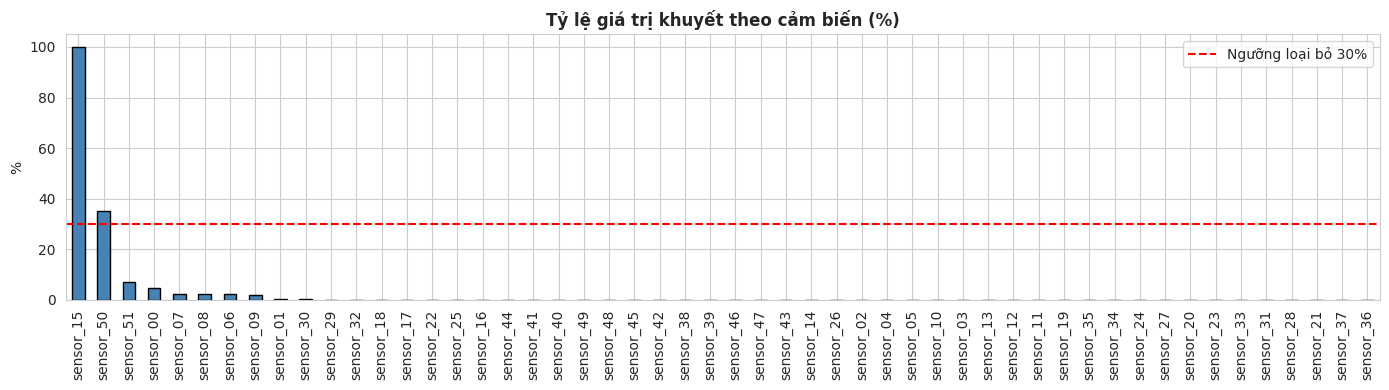

In [6]:
missing_pct = (df[sensor_cols].isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(10).round(2))

plt.figure(figsize=(14, 4))
missing_pct.plot(kind='bar', color='steelblue', edgecolor='black')
plt.axhline(MISSING_DROP * 100, color='red', ls='--', label=f'Ngưỡng loại bỏ {MISSING_DROP:.0%}')
plt.title('Tỷ lệ giá trị khuyết theo cảm biến (%)', fontweight='bold')
plt.ylabel('%'); plt.legend(); plt.tight_layout(); plt.show()

📌 **Notes (Giá trị khuyết):**
* `sensor_15` **trống hoàn toàn (100%)** → không có thông tin, phải loại bỏ.
* `sensor_50` thiếu **34,96%** dữ liệu – vượt ngưỡng 30% → loại bỏ.
* Các cảm biến còn lại thiếu rất ít: `sensor_51` 6,98%, `sensor_00` 4,63%, nhóm `sensor_06`–`sensor_09` khoảng 2–2,5%, phần còn lại < 0,2%. Với dữ liệu chuỗi thời gian đo mỗi phút, các khoảng trống ngắn này được **nội suy theo thời gian** (giá trị liền trước và liền sau gần như giống nhau) thay vì xóa dòng.

## 2. Biến trạng thái `machine_status`

machine_status
NORMAL        205836
RECOVERING     14477
BROKEN             7
Name: count, dtype: int64
machine_status
NORMAL        93.426 %
RECOVERING     6.571 %
BROKEN         0.003 %
Name: count, dtype: object


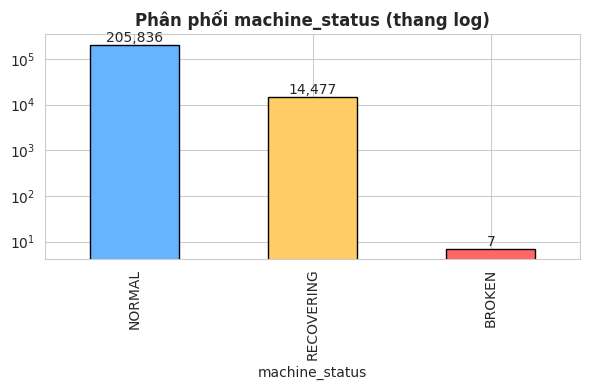

In [7]:
status_counts = df['machine_status'].value_counts()
print(status_counts)
print((status_counts / len(df) * 100).round(3).astype(str) + ' %')

ax = status_counts.plot(kind='bar', color=['#66b3ff', '#ffcc66', '#ff6666'], edgecolor='black', figsize=(6, 4))
ax.set_yscale('log')
ax.set_title('Phân phối machine_status (thang log)', fontweight='bold')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout(); plt.show()

In [8]:
broken_raw = df.index[df['machine_status'] == 'BROKEN']
print('Các thời điểm máy hỏng (BROKEN):')
for i, t in enumerate(broken_raw, 1):
    print(f'  Lần {i}: {t}')

print('\nKhoảng cách giữa các lần hỏng (ngày):')
print(pd.Series(broken_raw).diff().dt.total_seconds().div(86400).round(1).tolist()[1:])

# Thời gian RECOVERING sau mỗi lần hỏng
rec = (df['machine_status'] == 'RECOVERING').astype(int)
seg_id = (rec.diff() != 0).cumsum()
rec_len = rec[rec == 1].groupby(seg_id[rec == 1]).size() / 60
print('\nThời gian RECOVERING mỗi đợt (giờ):', rec_len.round(1).tolist())

Các thời điểm máy hỏng (BROKEN):
  Lần 1: 2018-04-12 21:55:00
  Lần 2: 2018-04-18 00:30:00
  Lần 3: 2018-05-19 03:18:00
  Lần 4: 2018-05-25 00:30:00
  Lần 5: 2018-06-28 22:00:00
  Lần 6: 2018-07-08 00:11:00
  Lần 7: 2018-07-25 14:00:00

Khoảng cách giữa các lần hỏng (ngày):
[5.1, 31.1, 5.9, 34.9, 9.1, 17.6]

Thời gian RECOVERING mỗi đợt (giờ): [15.7, 51.8, 21.9, 10.1, 139.8, 0.7, 1.2]


📌 **Notes (Biến trạng thái `machine_status`):**
* Dữ liệu có **220.320 dòng** (5 tháng, từ 01/04 đến 31/08/2018, mỗi phút một dòng): **205.836 dòng NORMAL (93,43%)**, **14.477 dòng RECOVERING (6,57%)** và chỉ **7 dòng BROKEN (0,003%)**.
* Dữ liệu **mất cân bằng cực mạnh**: chỉ có 7 lần hỏng → không đủ mẫu để huấn luyện mô hình phân lớp có giám sát. Vì vậy bài toán được giải bằng **phát hiện bất thường không giám sát**: mô hình chỉ học trạng thái bình thường, nhãn chỉ dùng để đánh giá.
* 7 lần hỏng: 12/04, 18/04, 19/05, 25/05, 28/06, 08/07, 25/07. Các lần hỏng có xu hướng **đi theo cặp** cách nhau 5–9 ngày (12/04–18/04, 19/05–25/05, 28/06–08/07), rồi yên ổn khoảng 1 tháng → có thể lần hỏng sau là do lần sửa trước chưa triệt để.
* Thời gian phục hồi rất khác nhau: từ **0,7 giờ** (08/07) đến **139,8 giờ ≈ 5,8 ngày** (28/06). Lần hỏng 28/06 là sự cố nghiêm trọng nhất.

## 3. Cảm biến theo thời gian
Dữ liệu được gộp theo giờ để vẽ cho nhẹ. Đường đỏ = thời điểm **BROKEN**, vùng cam = **RECOVERING**.

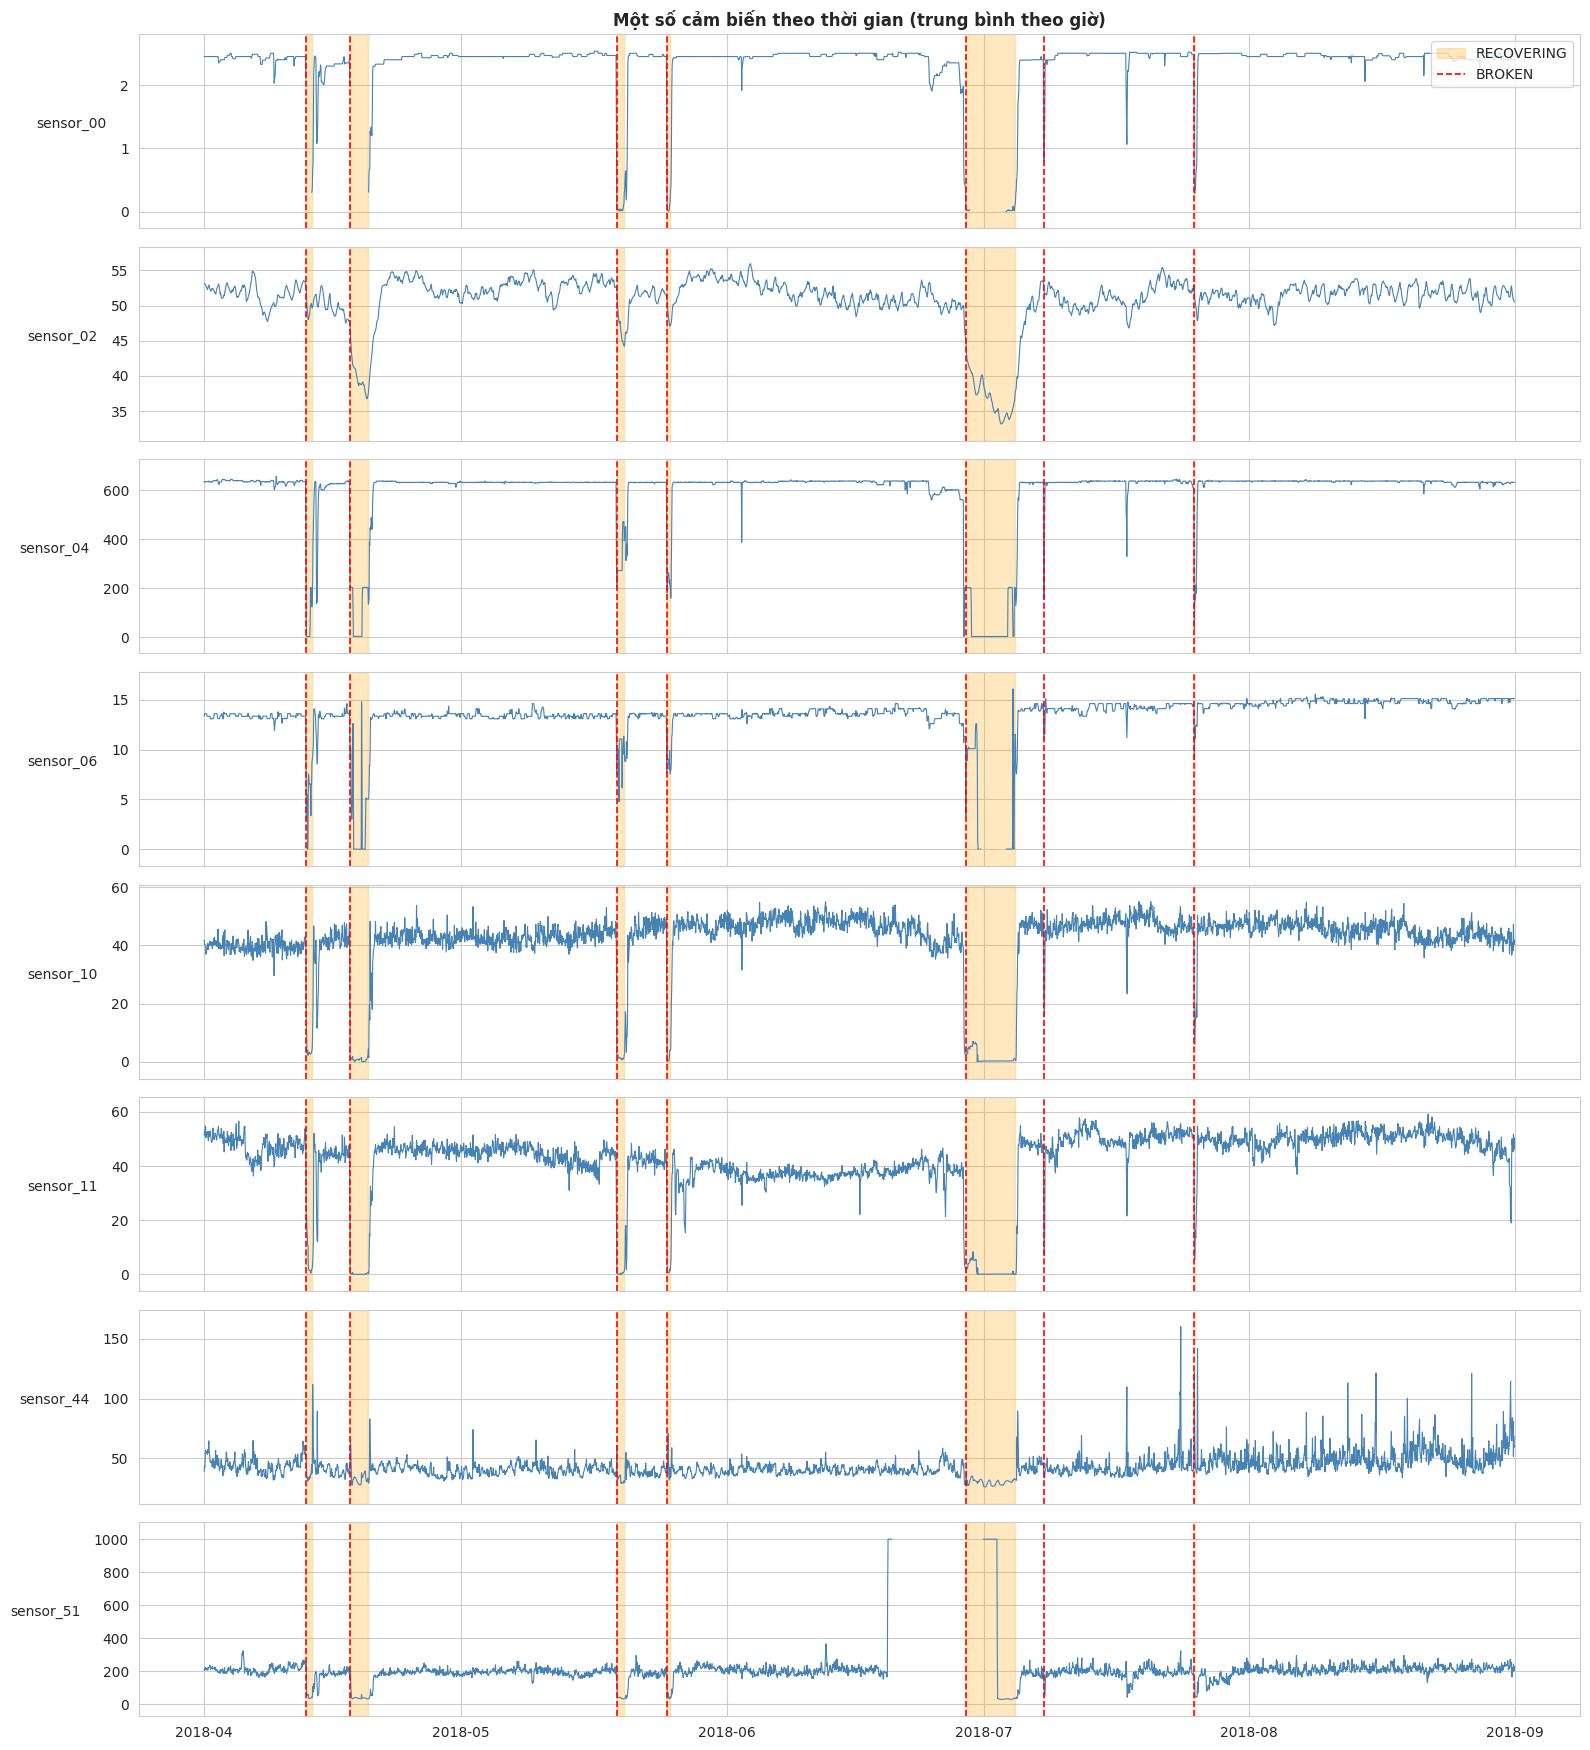

In [9]:
def mark_failures(ax, times, label=True):
    for i, t in enumerate(times):
        ax.axvline(t, color='red', ls='--', lw=1.2, label='BROKEN' if (label and i == 0) else None)

def shade_recovering(ax, index, status):
    ax.fill_between(index, 0, 1, where=(status == 'RECOVERING').values,
                    transform=ax.get_xaxis_transform(), color='orange', alpha=0.25, label='RECOVERING')

status_code_raw = df['machine_status'].map({'NORMAL': 0, 'RECOVERING': 1, 'BROKEN': 2})
hourly = df[sensor_cols].resample('1h').mean()
hourly_status = status_code_raw.resample('1h').max().map({0: 'NORMAL', 1: 'RECOVERING', 2: 'BROKEN'})

plot_sensors = [s for s in ['sensor_00', 'sensor_02', 'sensor_04', 'sensor_06',
                            'sensor_10', 'sensor_11', 'sensor_44', 'sensor_51'] if s in sensor_cols]
fig, axes = plt.subplots(len(plot_sensors), 1, figsize=(16, 2.2 * len(plot_sensors)), sharex=True)
for ax, s in zip(axes, plot_sensors):
    ax.plot(hourly.index, hourly[s], lw=0.8, color='steelblue')
    shade_recovering(ax, hourly.index, hourly_status)
    mark_failures(ax, broken_raw)
    ax.set_ylabel(s, rotation=0, labelpad=35)
axes[0].legend(loc='upper right')
axes[0].set_title('Một số cảm biến theo thời gian (trung bình theo giờ)', fontweight='bold')
plt.tight_layout(); plt.show()

📌 **Notes (Cảm biến theo thời gian):**
* Tại mỗi lần hỏng, nhiều cảm biến **tụt mạnh về gần 0** (`sensor_00`, `sensor_04`, `sensor_06`, `sensor_10`, `sensor_11`) – máy bơm dừng hoạt động – rồi trở lại mức cũ khi hết RECOVERING.
* **`sensor_51`** đột ngột **nhảy lên mức 1000** (giá trị tối đa của thang đo) từ khoảng 19–20/06 và giữ nguyên tới khi máy hỏng ngày 28/06 – đây là dấu hiệu bất thường rõ nhất xuất hiện **trước** một lần hỏng.
* Một số cảm biến **thay đổi mức nền** sau đợt sửa chữa dài 28/06–04/07: `sensor_06` tăng từ ~13,5 lên ~14,5–15; `sensor_11` tăng từ ~35–40 (tháng 6) lên ~50; `sensor_44` dao động mạnh hơn hẳn từ cuối tháng 7. Tức là **trạng thái "bình thường" của máy thay đổi theo thời gian (concept drift)** – một thách thức với mô hình chỉ học từ dữ liệu cũ.
* Với 2 lần hỏng 08/07 và 25/07, cảm biến gần như **không có biểu hiện báo trước**: giá trị chỉ tụt đột ngột đúng lúc hỏng.

## 4. Ma trận tương quan (Correlation Matrix)

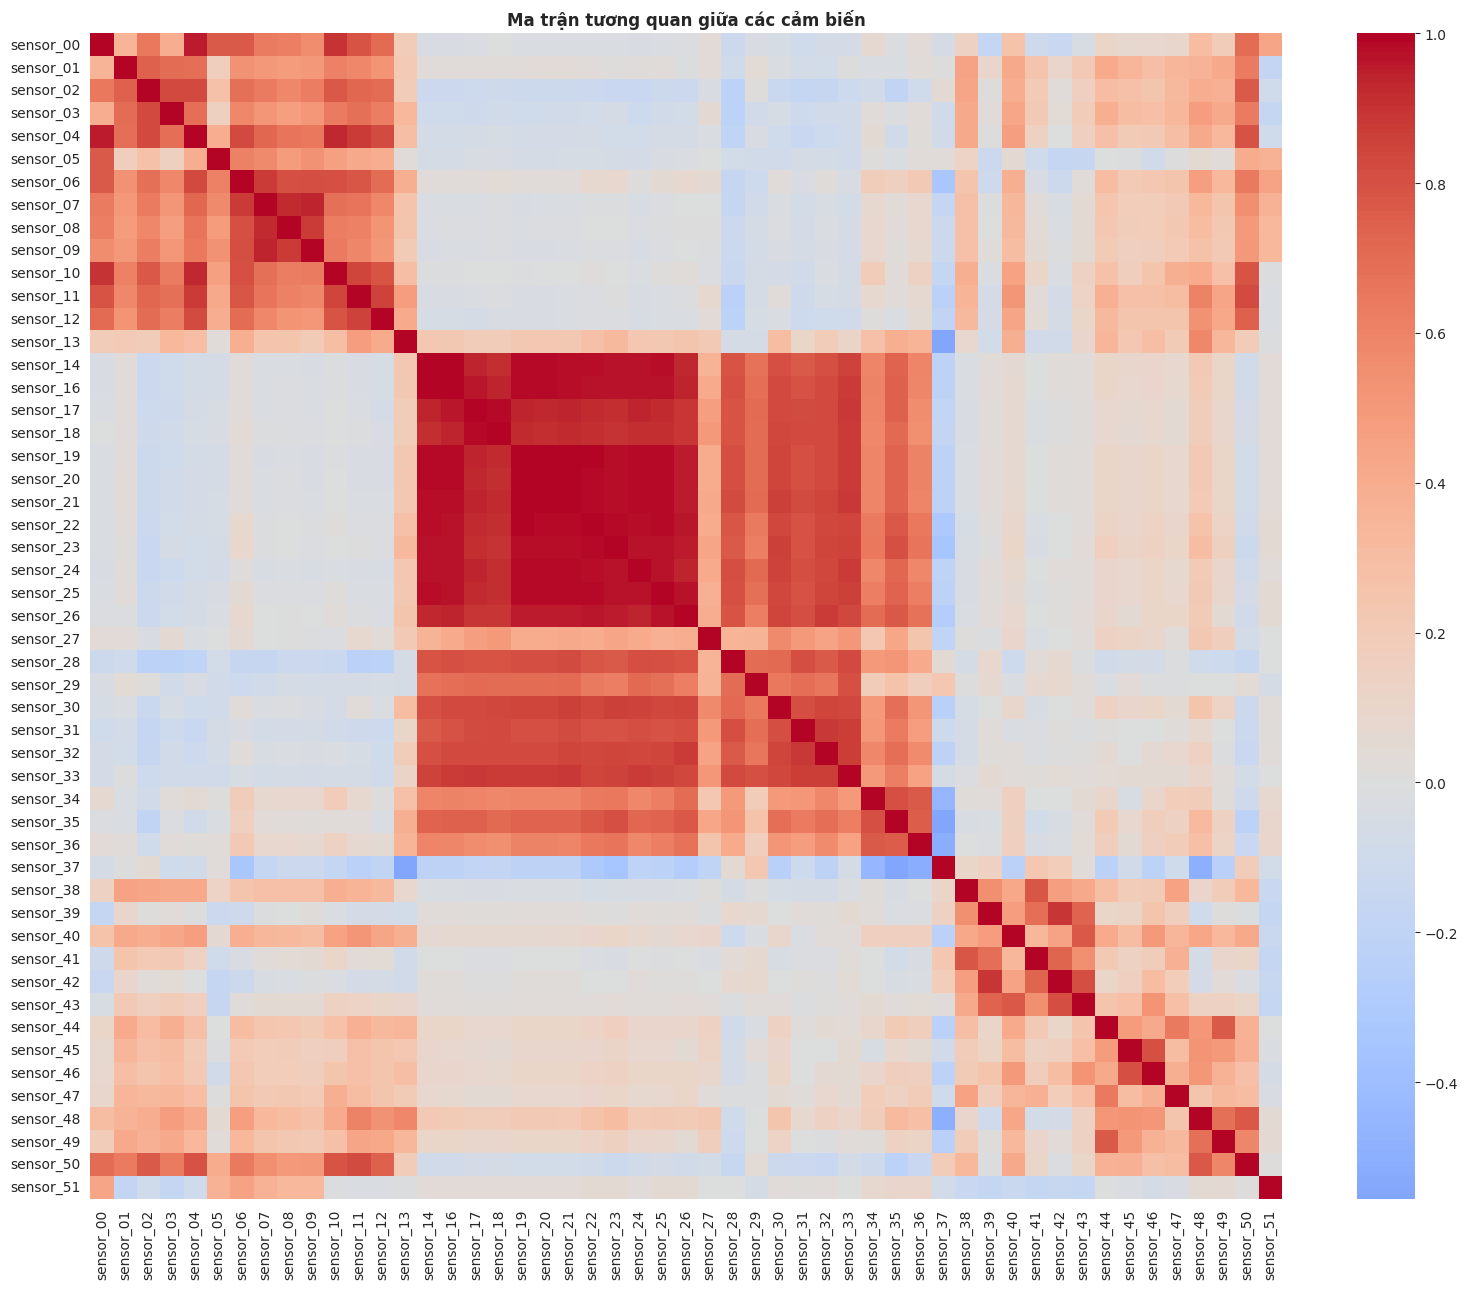

Số cặp cảm biến tương quan |r| > 0.9: 68
sensor_19  sensor_20   0.999
sensor_20  sensor_21   0.998
sensor_19  sensor_21   0.996
sensor_14  sensor_16   0.992
sensor_19  sensor_22   0.989
           sensor_24   0.988
sensor_22  sensor_23   0.988
sensor_20  sensor_22   0.987
sensor_21  sensor_24   0.987
sensor_14  sensor_19   0.987
dtype: float64


In [10]:
corr = hourly[sensor_cols].drop(columns=missing_pct[missing_pct > 99].index, errors='ignore').corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.title('Ma trận tương quan giữa các cảm biến', fontweight='bold')
plt.tight_layout(); plt.show()

high = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().loc[lambda s: s.abs() > 0.9])
print(f'Số cặp cảm biến tương quan |r| > 0.9: {len(high)}')
print(high.sort_values(ascending=False).head(10).round(3))

📌 **Notes (Ma trận tương quan):**
* Có **68 cặp cảm biến** tương quan rất mạnh (|r| > 0,9), ví dụ `sensor_19`–`sensor_20` (0,999), `sensor_20`–`sensor_21` (0,998), `sensor_14`–`sensor_16` (0,992).
* Các cảm biến tạo thành **nhóm biến động gần như giống hệt nhau**, nổi bật là nhóm `sensor_19`–`sensor_24` và cặp `sensor_14`–`sensor_16` → nhiều khả năng mỗi nhóm đo cùng một loại đại lượng ở các vị trí khác nhau của máy bơm.
* Dữ liệu 50 chiều nhưng có nhiều thông tin trùng lặp → có thể **nén về ít chiều hơn**. Đây là cơ sở để dùng **Autoencoder** (nén rồi tái tạo) và **PCA** (2 thành phần đầu đã giải thích 53,7% phương sai – xem phần PCA).

## 5. Kiểm tra outlier bằng thống kê (Boxplot / IQR)
Phương pháp thống kê đơn giản (chương 11 – *Statistical approaches*): điểm nằm ngoài `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` là outlier.

Top 10 cảm biến có tỷ lệ outlier (IQR) cao nhất (%):
sensor_09   31.210
sensor_20   27.040
sensor_14   26.400
sensor_19   26.370
sensor_21   25.450
sensor_16   22.160
sensor_17   17.220
sensor_18   17.190
sensor_30   16.860
sensor_27   14.870
dtype: float64

Tỷ lệ dòng có ít nhất 1 cảm biến outlier, theo trạng thái:
machine_status
BROKEN       100.000
NORMAL        73.110
RECOVERING    99.970
dtype: float64


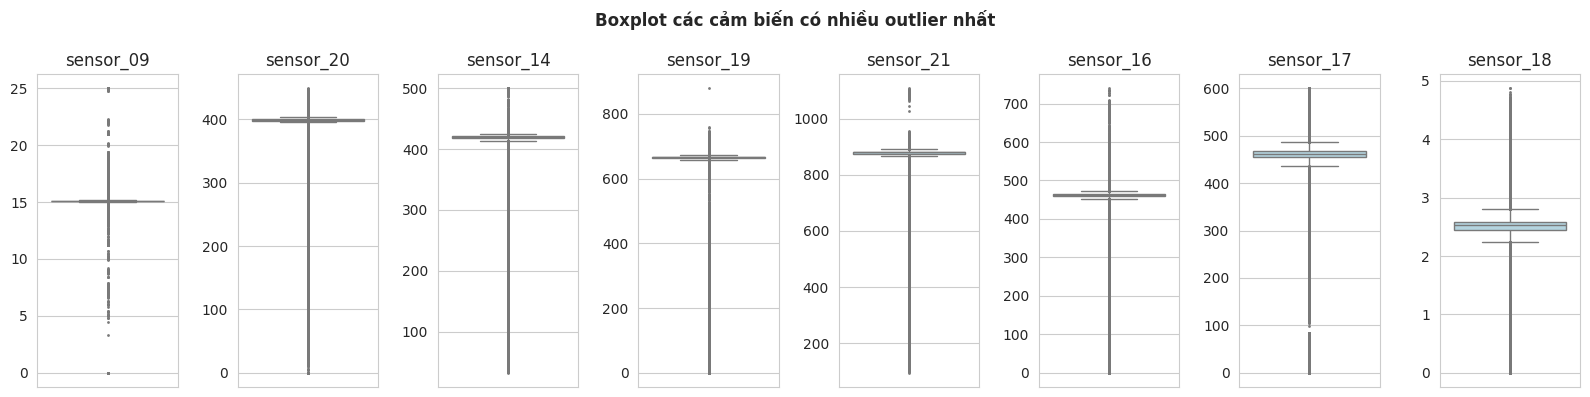

In [11]:
X_tmp = df[sensor_cols].drop(columns=missing_pct[missing_pct > 99].index, errors='ignore')
q1, q3 = X_tmp.quantile(0.25), X_tmp.quantile(0.75)
iqr = q3 - q1
outlier_pct = (((X_tmp < q1 - 1.5 * iqr) | (X_tmp > q3 + 1.5 * iqr)).mean() * 100).sort_values(ascending=False)
print('Top 10 cảm biến có tỷ lệ outlier (IQR) cao nhất (%):')
print(outlier_pct.head(10).round(2))

# Tỷ lệ outlier IQR theo trạng thái máy
any_out = ((X_tmp < q1 - 1.5 * iqr) | (X_tmp > q3 + 1.5 * iqr)).any(axis=1)
print('\nTỷ lệ dòng có ít nhất 1 cảm biến outlier, theo trạng thái:')
print((any_out.groupby(df['machine_status']).mean() * 100).round(2))

top = outlier_pct.head(8).index
fig, axes = plt.subplots(1, len(top), figsize=(16, 4))
for ax, s in zip(axes, top):
    sns.boxplot(y=df[s], ax=ax, color='lightblue', fliersize=1)
    ax.set_title(s); ax.set_ylabel('')
plt.suptitle('Boxplot các cảm biến có nhiều outlier nhất', fontweight='bold')
plt.tight_layout(); plt.show()

📌 **Notes (Outlier theo IQR):**
* Tỷ lệ outlier theo IQR rất cao ở một số cảm biến: `sensor_09` (31,2%), `sensor_20` (27,0%), `sensor_14` và `sensor_19` (26,4%), `sensor_21` (25,5%).
* Xét theo dòng: **73,1% số dòng NORMAL** có ít nhất một cảm biến bị IQR đánh dấu outlier, trong khi RECOVERING là 99,97% và BROKEN là 100%. Phương pháp IQR **bắt được mọi lần hỏng nhưng báo động nhầm gần như liên tục** → không dùng được để cảnh báo.
* Nguyên nhân: IQR xét **từng cảm biến riêng lẻ**, giả định phân phối đơn giản và **không xét ngữ cảnh thời gian**. Trong khi đó, phân phối các cảm biến lệch mạnh (các giá trị gần 0 lúc máy dừng kéo đuôi phân phối). Đây là lý do cần các phương pháp **đa biến** như Isolation Forest, LOF, Autoencoder.

# 🔄 Data Processing (Tiền xử lý)
1. Loại cảm biến thiếu quá nhiều dữ liệu và cảm biến hằng số.
2. Nội suy (interpolate) theo thời gian các giá trị khuyết còn lại.
3. Gộp (resample) theo khung **10 phút** → giảm nhiễu và giảm số dòng (~220k → ~22k).
4. Gán nhãn **`pre_failure`** = 1 cho khoảng `PRE_FAILURE_HOURS` giờ trước mỗi lần hỏng *(chỉ dùng để đánh giá, không dùng để huấn luyện)*.
5. **Chia train/test theo thời gian** (không chia ngẫu nhiên như bài phân lớp, vì dữ liệu là chuỗi thời gian – chia ngẫu nhiên sẽ làm "lộ" thông tin tương lai).
6. Chuẩn hóa `StandardScaler` – **chỉ fit trên dữ liệu NORMAL của tập train**.

In [12]:
# 1. Loại cảm biến thiếu nhiều / hằng số
miss = df[sensor_cols].isna().mean()
drop_missing = miss[miss > MISSING_DROP].index.tolist()
use_cols = [c for c in sensor_cols if c not in drop_missing]
drop_const = [c for c in use_cols if df[c].std() == 0]
use_cols = [c for c in use_cols if c not in drop_const]
print('Bỏ do thiếu dữ liệu:', drop_missing)
print('Bỏ do hằng số     :', drop_const)
print('Số cảm biến sử dụng:', len(use_cols))

# 2. Nội suy theo thời gian
X_clean = df[use_cols].interpolate(method='time', limit_direction='both').ffill().bfill()
print('Còn giá trị khuyết sau nội suy:', int(X_clean.isna().sum().sum()))

Bỏ do thiếu dữ liệu: ['sensor_15', 'sensor_50']
Bỏ do hằng số     : []
Số cảm biến sử dụng: 50
Còn giá trị khuyết sau nội suy: 0


In [13]:
# 3. Resample 10 phút: cảm biến lấy trung bình, trạng thái lấy mức nghiêm trọng nhất trong khung
data = X_clean.resample(RESAMPLE).mean()
data['status_code'] = status_code_raw.resample(RESAMPLE).max()
data = data.dropna()
data['status'] = data['status_code'].map({0: 'NORMAL', 1: 'RECOVERING', 2: 'BROKEN'})
broken_times = data.index[data['status'] == 'BROKEN']

# 4. Nhãn "trước hỏng" (chỉ để đánh giá)
WIN = pd.Timedelta(hours=PRE_FAILURE_HOURS)
data['pre_failure'] = 0
for t in broken_times:
    data.loc[(data.index >= t - WIN) & (data.index < t), 'pre_failure'] = 1

print('Kích thước sau resample:', data.shape)
print(data['status'].value_counts())
print(f'Số khung thuộc cửa sổ {PRE_FAILURE_HOURS}h trước hỏng:', int(data['pre_failure'].sum()))

Kích thước sau resample: (22032, 53)
status
NORMAL        20578
RECOVERING     1447
BROKEN            7
Name: count, dtype: int64
Số khung thuộc cửa sổ 24h trước hỏng: 1008


In [14]:
# 5. Chia train / test theo thời gian
split_time = data.index[0] + (data.index[-1] - data.index[0]) * TRAIN_FRAC
train_mask = data.index < split_time
test_mask = ~train_mask

# Dữ liệu dùng để HỌC: chỉ NORMAL trong giai đoạn train, bỏ các cửa sổ trước hỏng đã biết
normal_train = train_mask & (data['status'] == 'NORMAL').values & (data['pre_failure'] == 0).values
normal_idx = np.where(normal_train)[0]
cut = int(len(normal_idx) * 0.8)                       # 80% đầu để fit, 20% sau làm validation (chọn ngưỡng)
fit_mask = np.zeros(len(data), bool); fit_mask[normal_idx[:cut]] = True
val_mask = np.zeros(len(data), bool); val_mask[normal_idx[cut:]] = True

# Dữ liệu dùng để ĐÁNH GIÁ: các khung NORMAL trong giai đoạn test (bỏ BROKEN/RECOVERING vì máy đã hỏng rõ ràng)
eval_mask = test_mask & (data['status'] == 'NORMAL').values

test_broken = broken_times[broken_times >= split_time]
print('Thời điểm chia train/test:', split_time)
print(f'Số khung fit: {fit_mask.sum()} | validation: {val_mask.sum()} | đánh giá (test): {eval_mask.sum()}')
print(f'Số lần hỏng trong train: {(broken_times < split_time).sum()} | trong test: {len(test_broken)}')
if len(test_broken) == 0:
    print('⚠️ Tập test không có lần hỏng nào – hãy giảm TRAIN_FRAC.')

Thời điểm chia train/test: 2018-06-01 04:44:00
Số khung fit: 6108 | validation: 1528 | đánh giá (test): 12366
Số lần hỏng trong train: 4 | trong test: 3


📌 **Notes (Tiền xử lý & chia dữ liệu):**
* Sau khi loại `sensor_15`, `sensor_50` còn **50 cảm biến**; nội suy xong không còn giá trị khuyết.
* Gộp theo khung 10 phút: **22.032 khung** (20.578 NORMAL, 1.447 RECOVERING, 7 BROKEN). Cửa sổ 24h trước mỗi lần hỏng gồm **1.008 khung** (7 lần × 144 khung).
* Chia theo thời gian tại **01/06/2018**: giai đoạn train chứa **4 lần hỏng**, giai đoạn test chứa **3 lần hỏng** (28/06, 08/07, 25/07).
* Mô hình chỉ học trên **6.108 khung NORMAL** của giai đoạn train (đã bỏ các cửa sổ trước hỏng); **1.528 khung** tiếp theo làm validation để chọn ngưỡng; đánh giá trên **12.366 khung NORMAL** của giai đoạn test.

X_fit: (6108, 50) | X_val: (1528, 50) | X_all: (22032, 50)


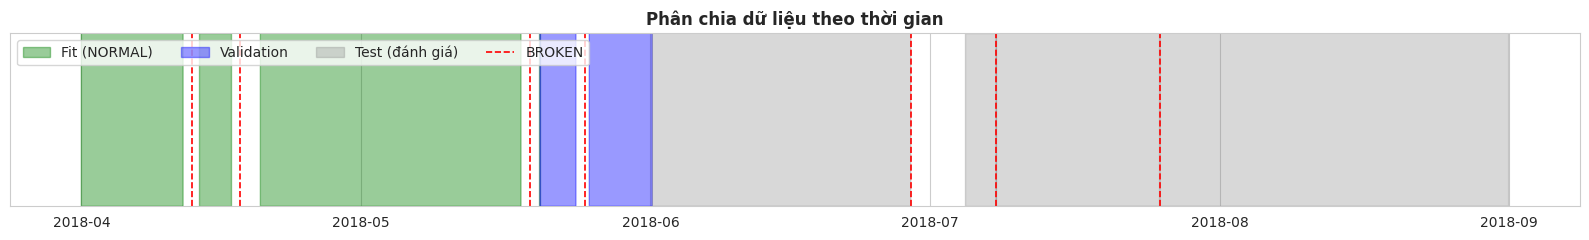

In [15]:
# 6. Chuẩn hóa – chỉ fit trên dữ liệu NORMAL của train
scaler = StandardScaler().fit(data.loc[fit_mask, use_cols])
Z = pd.DataFrame(scaler.transform(data[use_cols]), index=data.index, columns=use_cols)
X_fit, X_val, X_all = Z.values[fit_mask], Z.values[val_mask], Z.values
print('X_fit:', X_fit.shape, '| X_val:', X_val.shape, '| X_all:', X_all.shape)

fig, ax = plt.subplots(figsize=(16, 2.5))
ax.fill_between(data.index, 0, 1, where=fit_mask, color='green', alpha=0.4, label='Fit (NORMAL)', transform=ax.get_xaxis_transform())
ax.fill_between(data.index, 0, 1, where=val_mask, color='blue', alpha=0.4, label='Validation', transform=ax.get_xaxis_transform())
ax.fill_between(data.index, 0, 1, where=eval_mask, color='gray', alpha=0.3, label='Test (đánh giá)', transform=ax.get_xaxis_transform())
mark_failures(ax, broken_times)
ax.set_yticks([]); ax.legend(loc='upper left', ncol=4)
ax.set_title('Phân chia dữ liệu theo thời gian', fontweight='bold')
plt.tight_layout(); plt.show()

# 📏 Hàm đánh giá
Thay cho `print_score()` của bài phân lớp, với bài toán này ta đánh giá ở **2 mức**:

**Mức từng điểm (point-level)** trên các khung NORMAL của tập test, nhãn đúng là `pre_failure`:
Precision, Recall, F1, Confusion Matrix, ROC-AUC, PR-AUC (2 chỉ số cuối không phụ thuộc ngưỡng).

**Mức sự kiện (event-level)** – quan trọng hơn với bảo trì dự đoán:
* **Phát hiện được bao nhiêu lần hỏng** (có ít nhất một cảnh báo trong `PRE_FAILURE_HOURS` giờ trước khi hỏng).
* **Lead time:** cảnh báo đầu tiên xuất hiện sớm bao nhiêu giờ trước khi hỏng.
* **Số cảnh báo sai mỗi ngày:** số đợt báo động nằm ngoài các cửa sổ trước hỏng.
* **Alarm time %:** tỷ lệ thời gian đang báo động khi máy thực sự bình thường. Chỉ số này cần xem cùng với *Detected*: một mô hình báo động liên tục thì "phát hiện" được mọi lần hỏng nhưng vô dụng.

**Quy tắc báo động:** score vượt ngưỡng **liên tiếp `PERSIST` khung** mới báo động (lọc nhiễu, giảm báo động giả).
Ngưỡng = phân vị `THRESH_PCT` của score trên tập **validation** (dữ liệu bình thường mà mô hình chưa thấy khi fit).

In [16]:
STEP = pd.Timedelta(RESAMPLE)

def get_threshold(score, pct=THRESH_PCT):
    return np.percentile(np.asarray(score)[val_mask], pct)

def make_alarm(score, threshold, persist=PERSIST):
    flag = (pd.Series(np.asarray(score), index=data.index) > threshold).astype(int)
    return (flag.rolling(persist, min_periods=persist).sum() == persist).astype(int)

def evaluate(name, score, pct=THRESH_PCT, persist=PERSIST, verbose=True):
    score = pd.Series(np.asarray(score), index=data.index)
    thr = get_threshold(score, pct)
    alarm = make_alarm(score, thr, persist)

    # --- point-level ---
    y_true = data.loc[eval_mask, 'pre_failure'].values
    y_pred = alarm.values[eval_mask]
    s = score.values[eval_mask]
    res = {
        'Model': name,
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, s) if len(set(y_true)) > 1 else np.nan,
        'PR-AUC': average_precision_score(y_true, s) if len(set(y_true)) > 1 else np.nan,
    }

    # --- event-level ---
    detected, leads, per_event = 0, [], []
    for t in test_broken:
        w = alarm[(alarm.index >= t - WIN) & (alarm.index < t)]
        hits = w[w == 1]
        if len(hits):
            detected += 1
            lead = (t - hits.index[0]).total_seconds() / 3600
            leads.append(lead)
            per_event.append(f'{t}: cảnh báo sớm {lead:.1f} giờ')
        else:
            per_event.append(f'{t}: KHÔNG phát hiện')
    fa_zone = eval_mask & (data['pre_failure'] == 0).values
    a = alarm.where(fa_zone, 0)
    episodes = int(((a == 1) & (a.shift(1, fill_value=0) == 0)).sum())
    n_days = fa_zone.sum() * STEP / pd.Timedelta('1D')
    res.update({
        'Detected': f'{detected}/{len(test_broken)}',
        'Mean lead (h)': np.mean(leads) if leads else np.nan,
        'False alarms/day': episodes / n_days if n_days > 0 else np.nan,
        'Alarm time %': 100 * alarm.values[fa_zone].mean() if fa_zone.any() else np.nan,
    })

    if verbose:
        print(f'===== {name} =====')
        print(f'Ngưỡng (phân vị {pct}%): {thr:.4f} | persist = {persist}')
        print(f"Precision {res['Precision']:.3f} | Recall {res['Recall']:.3f} | F1 {res['F1-Score']:.3f} | "
              f"ROC-AUC {res['ROC-AUC']:.3f} | PR-AUC {res['PR-AUC']:.3f}")
        print(f"Phát hiện {res['Detected']} lần hỏng | lead time TB {res['Mean lead (h)']:.1f} giờ | "
              f"{res['False alarms/day']:.2f} đợt cảnh báo sai/ngày | "
              f"báo động {res['Alarm time %']:.1f}% thời gian lúc máy bình thường")
        for e in per_event:
            print('  -', e)
        print('Confusion matrix [[TN FP] [FN TP]]:\n', confusion_matrix(y_true, y_pred))
    return res, alarm, thr

results_df = pd.DataFrame()
scores, alarms, thresholds = {}, {}, {}

# 🤖 Models Building (Baseline)
## 1. Isolation Forest
Ý tưởng: cắt dữ liệu ngẫu nhiên nhiều lần; điểm bất thường nằm lẻ loi nên **bị cô lập sau rất ít lần cắt** (đường đi trên cây ngắn).
Anomaly score = `-score_samples()` (càng cao càng bất thường).

In [17]:
t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples='auto', random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_fit)
scores['Isolation Forest'] = -iso.score_samples(X_all)
print(f'Thời gian: {time.time() - t0:.1f}s')

res, alarms['Isolation Forest'], thresholds['Isolation Forest'] = evaluate('Isolation Forest', scores['Isolation Forest'])
results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)

Thời gian: 0.5s
===== Isolation Forest =====
Ngưỡng (phân vị 99%): 0.6115 | persist = 3
Precision 0.458 | Recall 0.062 | F1 0.110 | ROC-AUC 0.612 | PR-AUC 0.114
Phát hiện 1/3 lần hỏng | lead time TB 4.5 giờ | 0.05 đợt cảnh báo sai/ngày | báo động 0.3% thời gian lúc máy bình thường
  - 2018-06-28 22:00:00: cảnh báo sớm 4.5 giờ
  - 2018-07-08 00:10:00: KHÔNG phát hiện
  - 2018-07-25 14:00:00: KHÔNG phát hiện
Confusion matrix [[TN FP] [FN TP]]:
 [[11902    32]
 [  405    27]]


## 2. Local Outlier Factor (LOF)
Ý tưởng: so **mật độ cục bộ** của một điểm với mật độ của `k` láng giềng gần nhất (k-distance, reachability distance).
LOF ≈ 1: điểm nằm trong cụm; LOF ≫ 1: điểm thưa hơn hẳn láng giềng → bất thường.
`novelty=True` để mô hình học trên dữ liệu bình thường rồi chấm điểm dữ liệu mới.

In [18]:
t0 = time.time()
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof.fit(X_fit)
scores['LOF'] = -lof.score_samples(X_all)
print(f'Thời gian: {time.time() - t0:.1f}s')

res, alarms['LOF'], thresholds['LOF'] = evaluate('LOF', scores['LOF'])
results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)

Thời gian: 0.6s
===== LOF =====
Ngưỡng (phân vị 99%): 2.6275 | persist = 3
Precision 0.083 | Recall 0.350 | F1 0.134 | ROC-AUC 0.667 | PR-AUC 0.082
Phát hiện 2/3 lần hỏng | lead time TB 17.2 giờ | 1.54 đợt cảnh báo sai/ngày | báo động 14.0% thời gian lúc máy bình thường
  - 2018-06-28 22:00:00: cảnh báo sớm 24.0 giờ
  - 2018-07-08 00:10:00: KHÔNG phát hiện
  - 2018-07-25 14:00:00: cảnh báo sớm 10.5 giờ
Confusion matrix [[TN FP] [FN TP]]:
 [[10262  1672]
 [  281   151]]


## 3. Autoencoder
Ý tưởng (*reconstruction-based*): mạng neural học **nén** dữ liệu bình thường xuống ít chiều (bottleneck) rồi **tái tạo** lại.
Dữ liệu lạ (sắp hỏng) sẽ bị tái tạo kém → **sai số tái tạo (MSE)** cao → bất thường.

Kiến trúc: `n_features → 32 → 16 → 8 → 16 → 32 → n_features`. Dùng TensorFlow/Keras (có sẵn trên Kaggle); nếu môi trường không có TensorFlow sẽ tự dùng `MLPRegressor` của scikit-learn.

I0000 00:00:1794987039.922412    7572 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794987042.011747    7572 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0


E0000 00:00:1794987042.301144    7572 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Thời gian: 12.1s


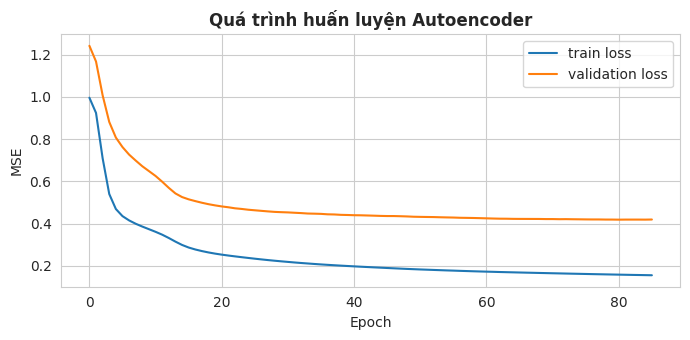

===== Autoencoder =====
Ngưỡng (phân vị 99%): 3.1467 | persist = 3
Precision 0.107 | Recall 0.333 | F1 0.162 | ROC-AUC 0.594 | PR-AUC 0.153
Phát hiện 1/3 lần hỏng | lead time TB 24.0 giờ | 0.21 đợt cảnh báo sai/ngày | báo động 10.1% thời gian lúc máy bình thường
  - 2018-06-28 22:00:00: cảnh báo sớm 24.0 giờ
  - 2018-07-08 00:10:00: KHÔNG phát hiện
  - 2018-07-25 14:00:00: KHÔNG phát hiện
Confusion matrix [[TN FP] [FN TP]]:
 [[10733  1201]
 [  288   144]]


In [19]:
try:
    import tensorflow as tf
    from tensorflow import keras
    HAS_TF = True
    print('TensorFlow', tf.__version__)
except ImportError:
    from sklearn.neural_network import MLPRegressor
    HAS_TF = False
    print('Không có TensorFlow → dùng MLPRegressor (scikit-learn)')

def fit_autoencoder(X_tr, X_va, bottleneck=8, epochs=100):
    n = X_tr.shape[1]
    if HAS_TF:
        tf.random.set_seed(RANDOM_STATE)
        inp = keras.Input(shape=(n,))
        x = keras.layers.Dense(32, activation='relu')(inp)
        x = keras.layers.Dense(16, activation='relu')(x)
        z = keras.layers.Dense(bottleneck, activation='relu')(x)
        x = keras.layers.Dense(16, activation='relu')(z)
        x = keras.layers.Dense(32, activation='relu')(x)
        out = keras.layers.Dense(n, activation='linear')(x)
        model = keras.Model(inp, out)
        model.compile(optimizer='adam', loss='mse')
        es = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
        hist = model.fit(X_tr, X_tr, validation_data=(X_va, X_va), epochs=epochs,
                         batch_size=256, callbacks=[es], verbose=0)
        return (lambda X: model.predict(X, verbose=0)), hist.history
    model = MLPRegressor(hidden_layer_sizes=(32, 16, bottleneck, 16, 32), activation='relu',
                         max_iter=epochs, early_stopping=True, random_state=RANDOM_STATE)
    model.fit(X_tr, X_tr)
    return model.predict, {'loss': model.loss_curve_}

t0 = time.time()
ae_predict, ae_hist = fit_autoencoder(X_fit, X_val, bottleneck=8)
recon = ae_predict(X_all)
ae_err = pd.DataFrame((X_all - recon) ** 2, index=data.index, columns=use_cols)  # sai số theo từng cảm biến
scores['Autoencoder'] = ae_err.mean(axis=1).values
print(f'Thời gian: {time.time() - t0:.1f}s')

plt.figure(figsize=(7, 3.5))
plt.plot(ae_hist['loss'], label='train loss')
if 'val_loss' in ae_hist: plt.plot(ae_hist['val_loss'], label='validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Quá trình huấn luyện Autoencoder', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

res, alarms['Autoencoder'], thresholds['Autoencoder'] = evaluate('Autoencoder', scores['Autoencoder'])
results_df = pd.concat([results_df, pd.DataFrame([res])], ignore_index=True)

## 📊 Bảng kết quả baseline

In [20]:
results_df

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Detected,Mean lead (h),False alarms/day,Alarm time %
0,Isolation Forest,0.458,0.062,0.110,0.612,0.114,1/3,4.500,0.048,0.268
1,LOF,0.083,0.350,0.134,0.667,0.082,2/3,17.250,1.544,14.010
2,Autoencoder,0.107,0.333,0.162,0.594,0.153,1/3,24.000,0.205,10.064


📌 **Notes (Kết quả baseline):**
* **Isolation Forest** rất "thận trọng": chỉ báo động **0,3% thời gian** lúc máy bình thường (precision cao nhất 0,458) nhưng chỉ phát hiện **1/3** lần hỏng, cảnh báo sớm 4,5 giờ.
* **LOF** nhạy nhất: phát hiện **2/3** lần hỏng (28/06 sớm 24 giờ, 25/07 sớm 10,5 giờ), đổi lại báo động **14% thời gian** và ~1,5 đợt báo động nhầm mỗi ngày.
* **Autoencoder**: phát hiện **1/3** (28/06, sớm 24 giờ), báo động 10,1% thời gian. Đường loss cho thấy mô hình hội tụ ổn định (dừng sớm sau ~85 epoch); loss validation (~0,42) cao hơn train (~0,16) do dữ liệu validation nằm ở giai đoạn sau, máy đã thay đổi trạng thái một chút.
* **Lần hỏng 08/07 không mô hình nào phát hiện trước** – khớp với nhận xét ở EDA: sự cố xảy ra đột ngột, không có dấu hiệu báo trước.
* Phần lớn "báo động nhầm" của LOF và Autoencoder nằm trong đoạn **19/06–28/06**, lúc `sensor_51` bị kẹt ở mức 1000. Đoạn này thực ra là **dấu hiệu bất thường thật xuất hiện ~9 ngày trước lần hỏng 28/06**, nhưng bị tính là nhầm vì nằm ngoài cửa sổ đánh giá 24 giờ.
* Precision/Recall/F1 theo từng khung đều thấp (F1 ≤ 0,16) – điều này bình thường ở bài toán này vì không phải khung nào trong 24 giờ trước hỏng cũng có biểu hiện bất thường. Các chỉ số **Detected / Lead time / Alarm time %** phản ánh giá trị thực tế tốt hơn.

# 🔧 Hyperparameter Tuning
Thử kết hợp **tham số mô hình × quy tắc báo động**:
* Isolation Forest: `n_estimators`, `max_samples`
* LOF: `n_neighbors`
* Autoencoder: kích thước `bottleneck`
* Quy tắc báo động (cả 3 mô hình): ngưỡng phân vị `THRESH_PCT` ∈ {95, 97.5, 99, 99.5} và `PERSIST` ∈ {1, 3, 6}

**Tiêu chí chọn cấu hình tốt nhất** (theo mục tiêu bảo trì dự đoán, không dùng F1 vì F1 bị chi phối bởi các khung đơn lẻ):
1. Loại các cấu hình báo động quá nhiều: `Alarm time %` > `MAX_ALARM_PCT` (mặc định 15%) – mô hình báo động gần như liên tục thì vô dụng dù "phát hiện" được mọi lần hỏng.
2. Ưu tiên **phát hiện được nhiều lần hỏng nhất** (`Detected`).
3. Nếu bằng nhau: chọn cấu hình **ít báo động nhầm hơn** (`Alarm time %` thấp), rồi **cảnh báo sớm hơn** (`Mean lead` cao).

⚠️ *Lưu ý ghi trong báo cáo:* dữ liệu chỉ có 7 lần hỏng nên việc tinh chỉnh được đánh giá trực tiếp trên giai đoạn test → kết quả sau tuning có thể **lạc quan hơn thực tế**.

In [21]:
tune_log = []

# Isolation Forest
for n_est in [100, 200, 500]:
    for ms in [256, 1024, 'auto']:
        m = IsolationForest(n_estimators=n_est, max_samples=ms, random_state=RANDOM_STATE, n_jobs=-1).fit(X_fit)
        sc = -m.score_samples(X_all)
        r, _, _ = evaluate('Isolation Forest', sc, verbose=False)
        tune_log.append({**r, 'params': f'n_estimators={n_est}, max_samples={ms}', '_score': sc})

# LOF
for k in [10, 20, 50, 100]:
    m = LocalOutlierFactor(n_neighbors=k, novelty=True, n_jobs=-1).fit(X_fit)
    sc = -m.score_samples(X_all)
    r, _, _ = evaluate('LOF', sc, verbose=False)
    tune_log.append({**r, 'params': f'n_neighbors={k}', '_score': sc})

# Autoencoder
ae_errs = {}
for b in [4, 8, 16]:
    pred, _ = fit_autoencoder(X_fit, X_val, bottleneck=b)
    err = pd.DataFrame((X_all - pred(X_all)) ** 2, index=data.index, columns=use_cols)
    ae_errs[b] = err
    r, _, _ = evaluate('Autoencoder', err.mean(axis=1).values, verbose=False)
    tune_log.append({**r, 'params': f'bottleneck={b}', '_score': err.mean(axis=1).values, '_b': b})

tune_df = pd.DataFrame(tune_log)
tune_df.drop(columns=[c for c in tune_df.columns if c.startswith('_')])

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Detected,Mean lead (h),False alarms/day,Alarm time %,params
0,Isolation Forest,0.438,0.065,0.113,0.641,0.130,1/3,4.667,0.072,0.302,"n_estimators=100, max_samples=256"
1,Isolation Forest,0.415,0.062,0.109,0.617,0.116,1/3,4.500,0.072,0.318,"n_estimators=100, max_samples=1024"
2,Isolation Forest,0.438,0.065,0.113,0.641,0.130,1/3,4.667,0.072,0.302,"n_estimators=100, max_samples=auto"
3,Isolation Forest,0.458,0.062,0.110,0.612,0.114,1/3,4.500,0.048,0.268,"n_estimators=200, max_samples=256"
4,Isolation Forest,0.426,0.060,0.105,0.619,0.100,1/3,4.333,0.060,0.293,"n_estimators=200, max_samples=1024"
5,Isolation Forest,0.458,0.062,0.110,0.612,0.114,1/3,4.500,0.048,0.268,"n_estimators=200, max_samples=auto"
6,Isolation Forest,0.510,0.060,0.108,0.620,0.108,1/3,4.333,0.048,0.209,"n_estimators=500, max_samples=256"
7,Isolation Forest,0.482,0.062,0.111,0.635,0.112,1/3,4.500,0.060,0.243,"n_estimators=500, max_samples=1024"
8,Isolation Forest,0.510,0.060,0.108,0.620,0.108,1/3,4.333,0.048,0.209,"n_estimators=500, max_samples=auto"
9,LOF,0.072,0.387,0.121,0.620,0.052,3/3,22.111,3.029,18.016,n_neighbors=10


In [22]:
MAX_ALARM_PCT = 15   # bỏ các cấu hình báo động > 15% thời gian lúc máy bình thường

# Thử mọi kết hợp: tham số mô hình × ngưỡng × persist
grid = []
for _, row in tune_df.iterrows():
    for pct in [95, 97.5, 99, 99.5]:
        for p in [1, 3, 6]:
            r, al, thr = evaluate(row['Model'], row['_score'], pct=pct, persist=p, verbose=False)
            grid.append({**r, 'params': f"{row['params']}, pct={pct}, persist={p}",
                         'n_detected': int(r['Detected'].split('/')[0]),
                         '_score': row['_score'], '_alarm': al, '_thr': thr,
                         '_pct': pct, '_persist': p, '_b': row.get('_b')})
grid_df = pd.DataFrame(grid)

def pick_best(g):
    ok = g[g['Alarm time %'] <= MAX_ALARM_PCT]
    if ok.empty:                       # không cấu hình nào đạt → xét tất cả, vẫn ưu tiên ít báo động
        print(f"⚠️ {g['Model'].iloc[0]}: không có cấu hình nào báo động ≤ {MAX_ALARM_PCT}% → xét tất cả cấu hình")
        ok = g
    return ok.sort_values(['n_detected', 'Alarm time %', 'Mean lead (h)'],
                          ascending=[False, True, False]).iloc[0]

show_cols = ['Model', 'params', 'Detected', 'Mean lead (h)', 'False alarms/day', 'Alarm time %', 'PR-AUC']
print(f'Tổng số cấu hình đã thử: {len(grid_df)}')
print('\nTop 3 cấu hình của mỗi mô hình (sau khi loại cấu hình báo động > MAX_ALARM_PCT):')
top3 = (grid_df[grid_df['Alarm time %'] <= MAX_ALARM_PCT]
        .sort_values(['Model', 'n_detected', 'Alarm time %', 'Mean lead (h)'], ascending=[True, False, True, False])
        .groupby('Model').head(3))
display(top3[show_cols])

tuning_results_df = pd.DataFrame()
best_scores, best_alarms, best_cfg = {}, {}, {}
for m, g in grid_df.groupby('Model'):
    b = pick_best(g)
    r = b[[c for c in grid_df.columns if not c.startswith('_') and c != 'n_detected']].to_dict()
    r['Model'] = 'Tuned ' + m
    tuning_results_df = pd.concat([tuning_results_df, pd.DataFrame([r])], ignore_index=True)
    best_scores[m], best_alarms[m] = b['_score'], b['_alarm']
    best_cfg[m] = {'thr': b['_thr'], 'pct': b['_pct'], 'persist': b['_persist'], 'b': b['_b']}

all_results = pd.concat([results_df, tuning_results_df], ignore_index=True)
all_results

Tổng số cấu hình đã thử: 192

Top 3 cấu hình của mỗi mô hình (sau khi loại cấu hình báo động > MAX_ALARM_PCT):


,Model,params,Detected,Mean lead (h),False alarms/day,Alarm time %,PR-AUC
189,Autoencoder,"bottleneck=16, pct=99.5, persist=1",2/3,12.083,0.084,9.846,0.145
177,Autoencoder,"bottleneck=8, pct=99.5, persist=1",2/3,12.083,0.157,9.930,0.177
165,Autoencoder,"bottleneck=4, pct=99.5, persist=1",2/3,12.083,0.181,9.963,0.247
95,Isolation Forest,"n_estimators=500, max_samples=1024, pct=99.5, ...",1/3,3.833,0.024,0.168,0.112
23,Isolation Forest,"n_estimators=100, max_samples=1024, pct=99.5, ...",1/3,3.833,0.024,0.176,0.116
59,Isolation Forest,"n_estimators=200, max_samples=1024, pct=99.5, ...",1/3,3.833,0.024,0.176,0.100
150,LOF,"n_neighbors=100, pct=99, persist=1",3/3,21.167,2.039,13.927,0.307
129,LOF,"n_neighbors=20, pct=99.5, persist=1",3/3,19.611,2.751,14.890,0.082
140,LOF,"n_neighbors=50, pct=99, persist=6",2/3,15.833,0.278,11.254,0.280


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Detected,Mean lead (h),False alarms/day,Alarm time %,params
0,Isolation Forest,0.458,0.062,0.110,0.612,0.114,1/3,4.500,0.048,0.268,NaN
1,LOF,0.083,0.350,0.134,0.667,0.082,2/3,17.250,1.544,14.010,NaN
2,Autoencoder,0.107,0.333,0.162,0.594,0.153,1/3,24.000,0.205,10.064,NaN
3,Tuned Autoencoder,0.110,0.336,0.166,0.637,0.145,2/3,12.083,0.084,9.846,"bottleneck=16, pct=99.5, persist=1"
4,Tuned Isolation Forest,0.535,0.053,0.097,0.635,0.112,1/3,3.833,0.024,0.168,"n_estimators=500, max_samples=1024, pct=99.5, ..."
5,Tuned LOF,0.086,0.361,0.139,0.718,0.307,3/3,21.167,2.039,13.927,"n_neighbors=100, pct=99, persist=1"


📌 **Notes (Tuning):**
* Đã thử **192 cấu hình** (tham số mô hình × ngưỡng × persist), chọn theo tiêu chí: báo động ≤ 15% thời gian → phát hiện nhiều lần hỏng nhất → ít báo động nhầm nhất.
* **LOF** (`n_neighbors=100`, ngưỡng phân vị 99%, persist = 1): phát hiện **3/3** lần hỏng, cảnh báo sớm trung bình **21,2 giờ**, nhưng báo động 13,9% thời gian và ~**2 đợt báo nhầm/ngày**. Lưu ý: với persist = 1, một khung vượt ngưỡng đã báo động, nên 2 lần hỏng 08/07 và 25/07 được "phát hiện" nhờ vài điểm nhọn lẻ tẻ trong 24 giờ trước đó – xem hình phóng to, các điểm này không khác gì những điểm báo nhầm ở thời điểm khác. Kết quả 3/3 vì vậy cần được hiểu thận trọng.
* **Autoencoder** (`bottleneck=16`, phân vị 99,5%, persist = 1): phát hiện **2/3**, báo nhầm rất ít (**0,08 đợt/ngày**). Lần hỏng 28/06 được cảnh báo sớm 24 giờ; lần thứ hai chỉ được phát hiện sát thời điểm hỏng (lead time trung bình 12,1 giờ).
* **Isolation Forest** (`n_estimators=500`, `max_samples=1024`, phân vị 99,5%): vẫn chỉ **1/3**, cảnh báo sớm 3,8 giờ, nhưng gần như không báo nhầm (0,17% thời gian).
* **Tham số ảnh hưởng nhiều nhất là quy tắc báo động** (ngưỡng phân vị và persist), không phải tham số của mô hình: cùng một mô hình, đổi ngưỡng/persist làm số lần phát hiện thay đổi từ 1/3 đến 3/3. Đây là **đánh đổi trực tiếp giữa phát hiện sớm và báo động nhầm**.
* ⚠️ Do chỉ có 3 lần hỏng trong test và việc chọn cấu hình dựa trên chính giai đoạn test, kết quả sau tuning **có thể lạc quan hơn thực tế**.

# 🧭 Cảm biến nào lệch nhiều nhất trước khi hỏng? (tương đương Feature Importance)
1. **Autoencoder:** tỷ lệ *sai số tái tạo trong cửa sổ trước hỏng / sai số lúc bình thường* của từng cảm biến.
2. **Z-score:** độ lệch trung bình |z| của từng cảm biến trong cửa sổ trước hỏng so với lúc bình thường (không phụ thuộc mô hình).

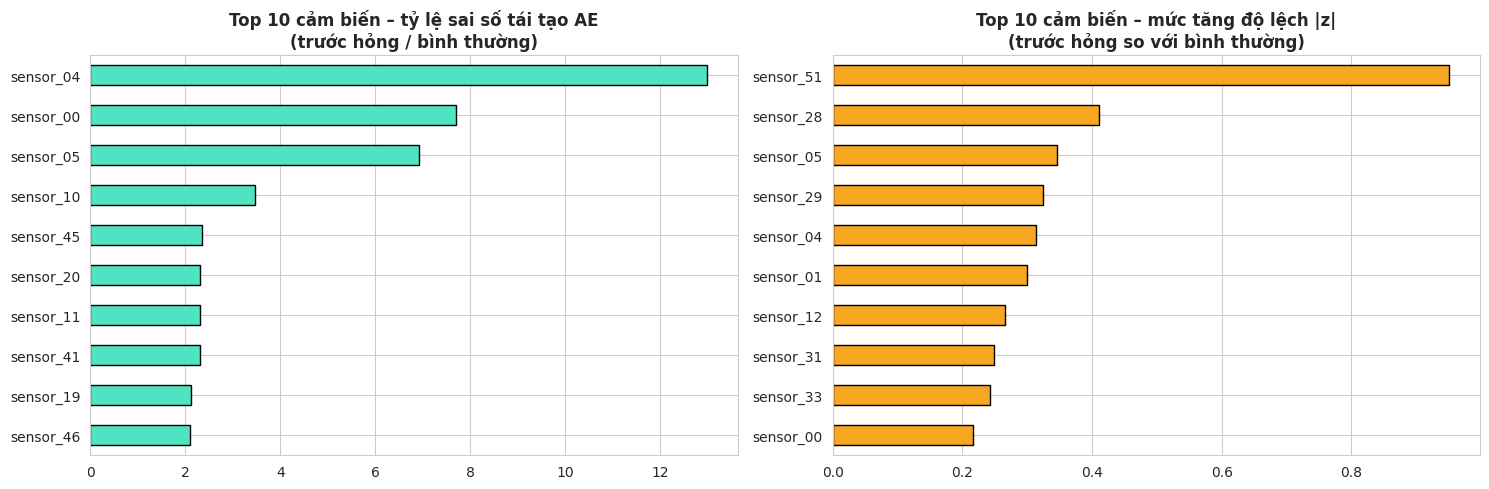

=== TOP 5 CẢM BIẾN CẦN THEO DÕI ===
sensor_04   12.980
sensor_00    7.700
sensor_05    6.920
sensor_10    3.470
sensor_45    2.350


In [23]:
b_best = best_cfg['Autoencoder']['b']
err_best = ae_errs[b_best] if b_best in ae_errs else ae_err
pre_zone = (data['pre_failure'] == 1).values & (data['status'] == 'NORMAL').values
norm_zone = eval_mask & (data['pre_failure'] == 0).values

ae_ratio = (err_best[pre_zone].mean() / err_best[norm_zone].mean()).sort_values(ascending=False)
z_dev = (Z[pre_zone].abs().mean() - Z[norm_zone].abs().mean()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ae_ratio.head(10).iloc[::-1].plot(kind='barh', ax=axes[0], color='#50E3C2', edgecolor='black')
axes[0].set_title('Top 10 cảm biến – tỷ lệ sai số tái tạo AE\n(trước hỏng / bình thường)', fontweight='bold')
z_dev.head(10).iloc[::-1].plot(kind='barh', ax=axes[1], color='#F5A623', edgecolor='black')
axes[1].set_title('Top 10 cảm biến – mức tăng độ lệch |z|\n(trước hỏng so với bình thường)', fontweight='bold')
plt.tight_layout(); plt.show()

key_sensors = ae_ratio.head(5).index.tolist()
print('=== TOP 5 CẢM BIẾN CẦN THEO DÕI ===')
print(ae_ratio.head(5).round(2).to_string())

📌 **Notes (Cảm biến chủ chốt):**
* Theo sai số tái tạo của Autoencoder, các cảm biến lệch mạnh nhất trong 24 giờ trước hỏng là **`sensor_04`** (gấp ~13 lần lúc bình thường), **`sensor_00`** (~7,7 lần), **`sensor_05`** (~6,9 lần), `sensor_10` (~3,5 lần), `sensor_45` (~2,4 lần).
* Theo độ lệch z-score, **`sensor_51`** đứng đầu – do bị kẹt ở giá trị lớn nhất của thang đo (1000) trước lần hỏng 28/06; tiếp theo là `sensor_28`, `sensor_29` và lại có `sensor_05`, `sensor_04`.
* Cả hai cách đều cho thấy **`sensor_04`, `sensor_00`, `sensor_05`** là nhóm cảm biến phản ánh rõ nhất tình trạng sắp hỏng. Kết quả khớp với EDA: `sensor_00`, `sensor_04` là những cảm biến tụt rõ nhất quanh mỗi lần hỏng.
* Do tên gốc của cảm biến đã bị ẩn danh, bài chỉ xác định được **cảm biến nào** cần theo dõi, chưa kết luận được bộ phận vật lý nào của máy bơm gặp vấn đề.

# 📈 Trực quan hóa kết quả
## 1. Anomaly score theo thời gian (3 mô hình sau tuning)

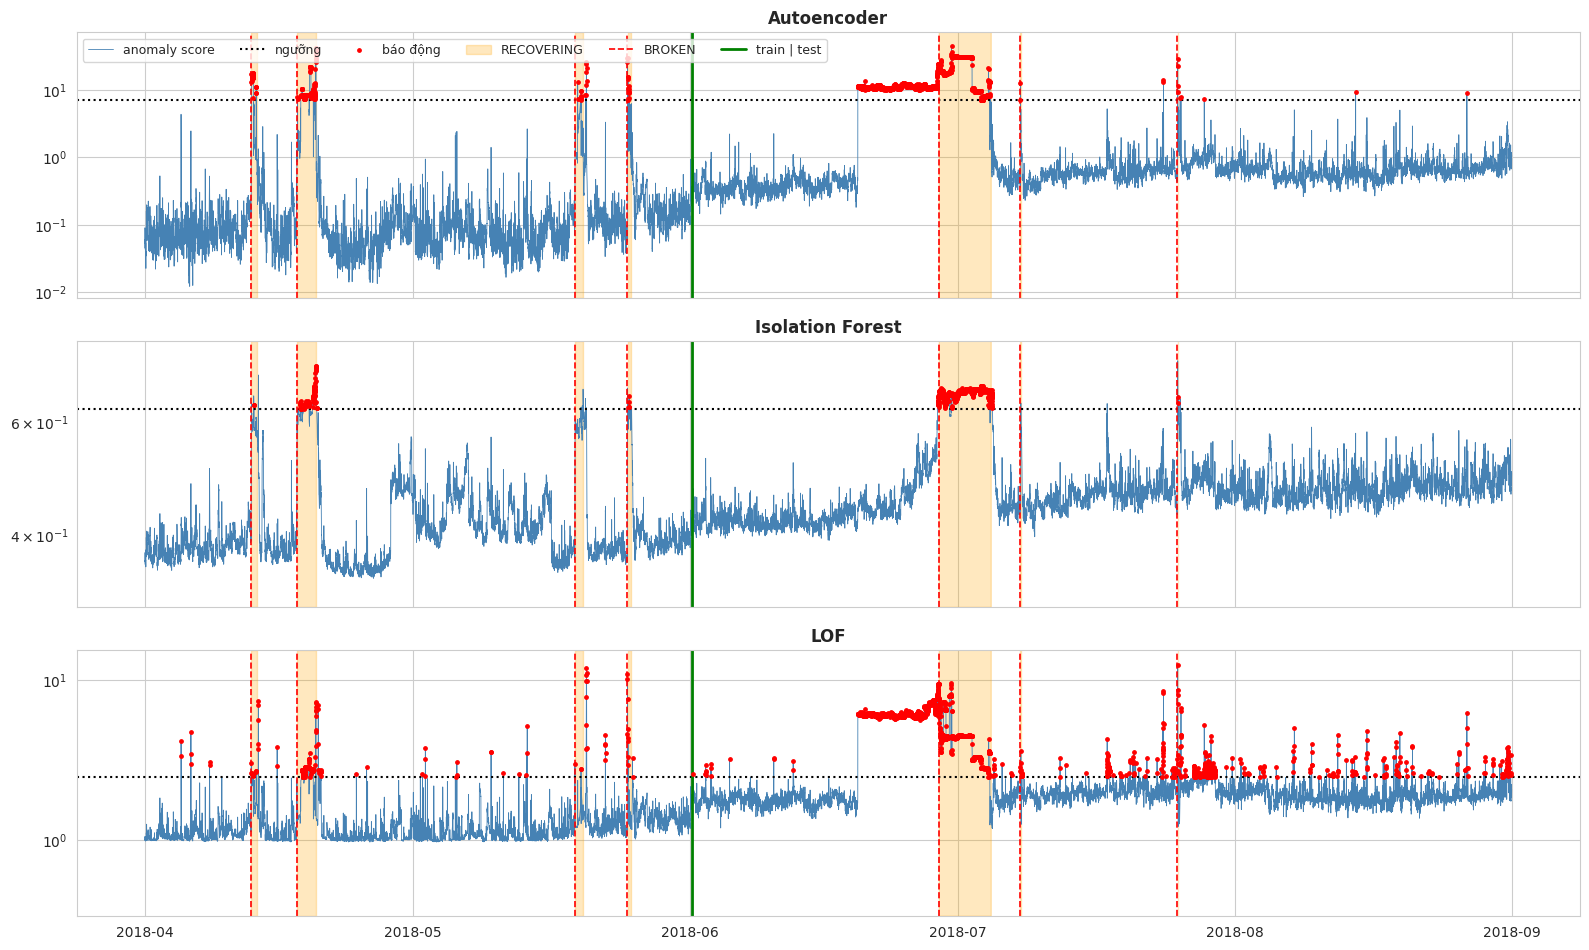

In [24]:
models = list(best_scores.keys())
fig, axes = plt.subplots(len(models), 1, figsize=(16, 3.2 * len(models)), sharex=True)
for ax, m in zip(axes, models):
    s = pd.Series(best_scores[m], index=data.index)
    ax.plot(s.index, s, lw=0.6, color='steelblue', label='anomaly score')
    ax.axhline(best_cfg[m]['thr'], color='black', ls=':', label='ngưỡng')
    al = best_alarms[m]
    ax.scatter(al.index[al == 1], s[al == 1], s=6, color='red', label='báo động', zorder=3)
    shade_recovering(ax, data.index, data['status'])
    mark_failures(ax, broken_times)
    ax.axvline(split_time, color='green', lw=2, label='train | test')
    ax.set_yscale('log'); ax.set_title(m, fontweight='bold')
axes[0].legend(loc='upper left', ncol=6, fontsize=9)
plt.tight_layout(); plt.show()

## 2. Phóng to quanh từng lần hỏng trong tập test

Mô hình dùng để minh họa: LOF


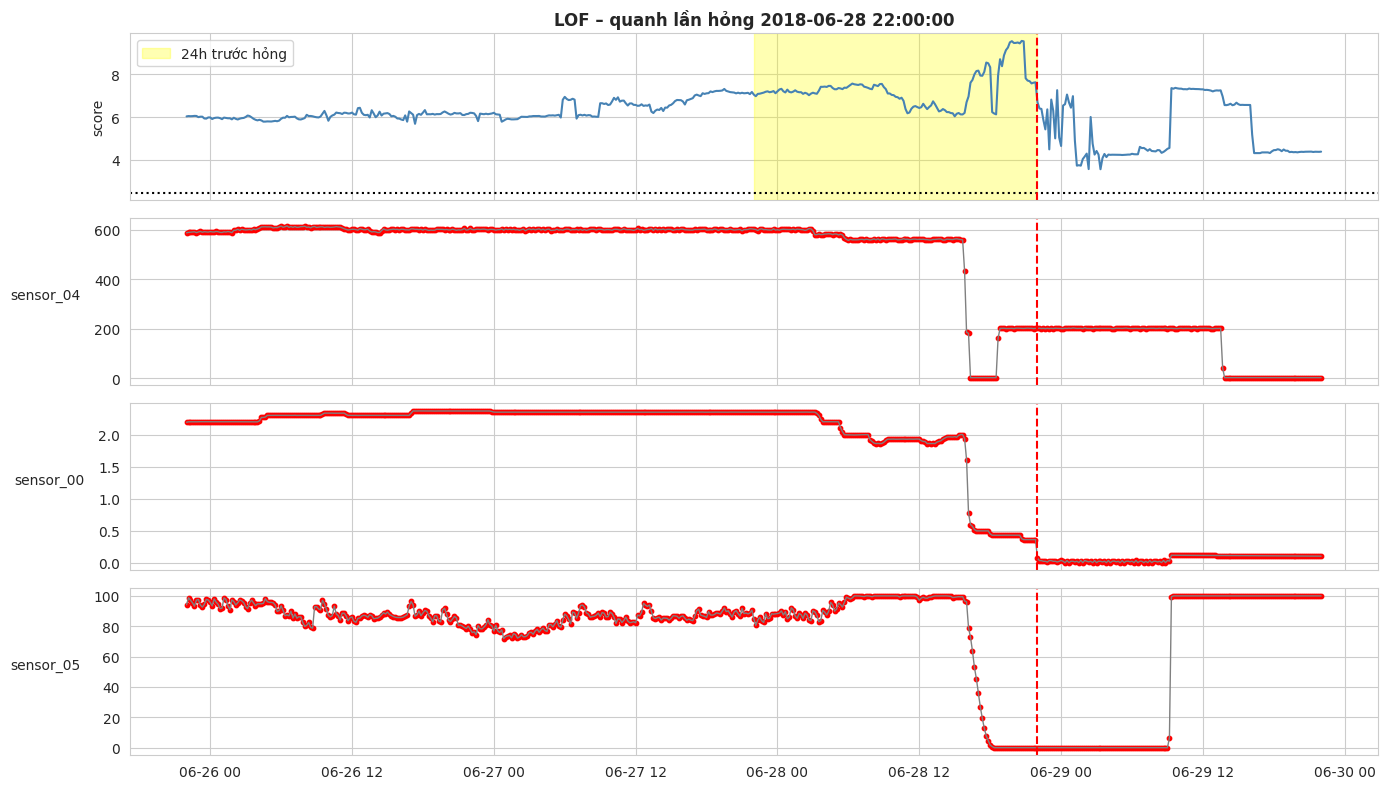

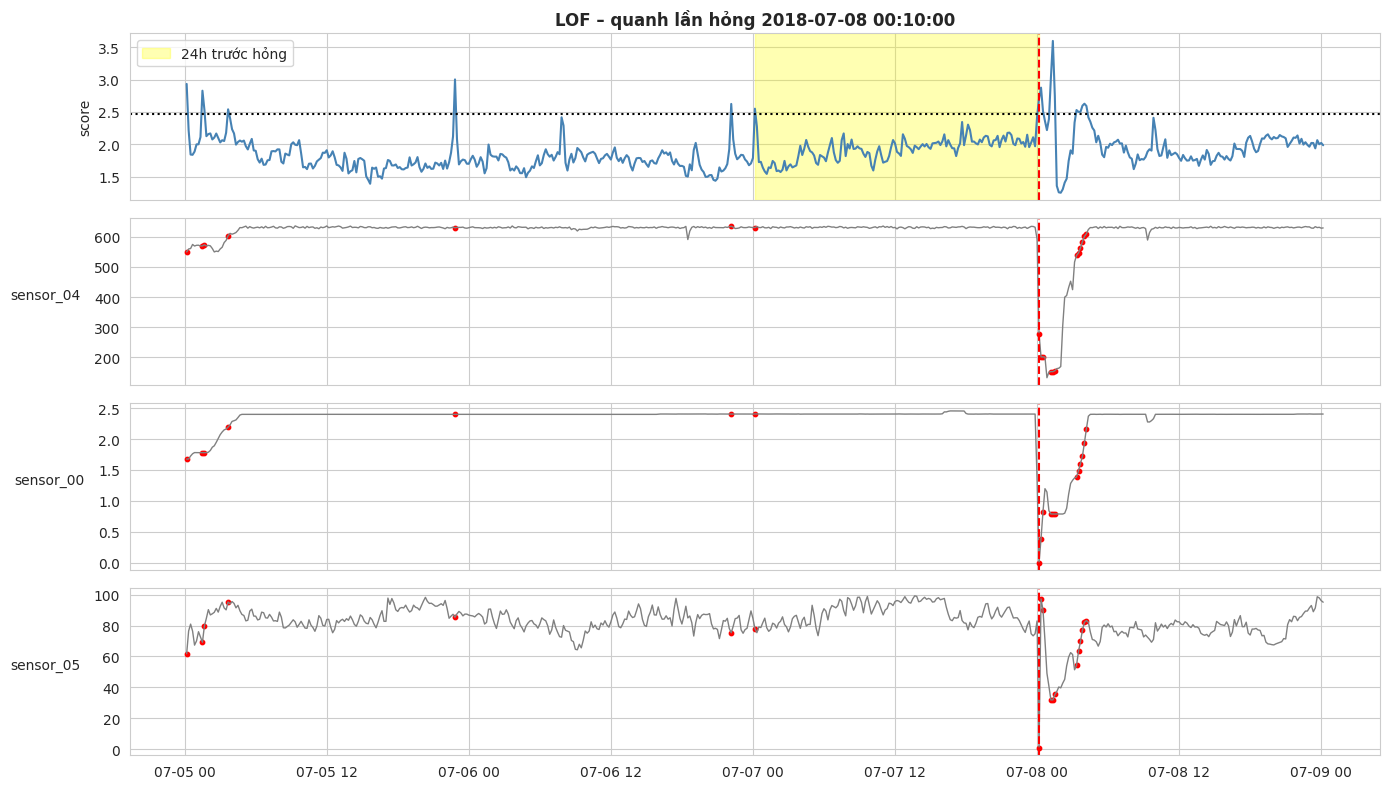

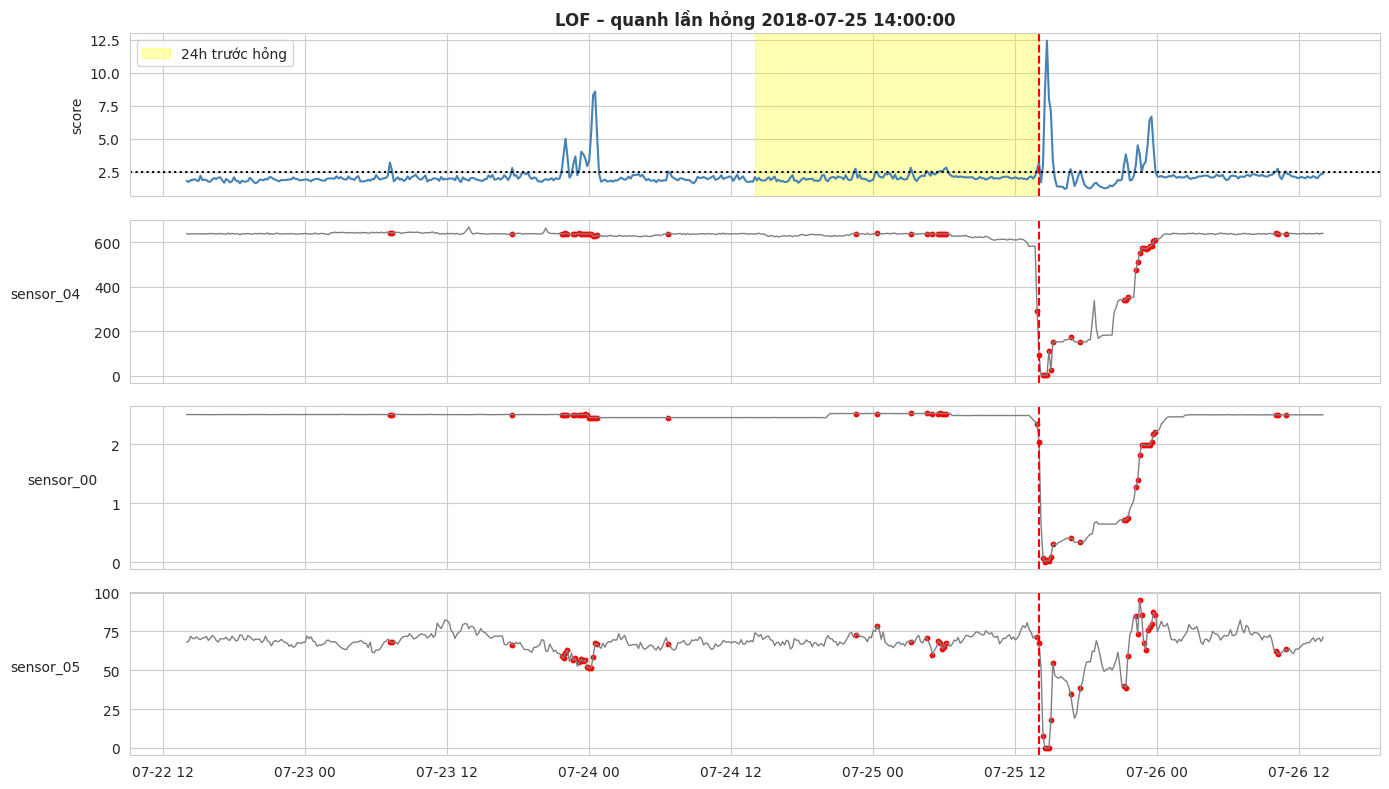

In [25]:
_rank = tuning_results_df.assign(n_det=tuning_results_df['Detected'].str.split('/').str[0].astype(int))
best_model = (_rank.sort_values(['n_det', 'Alarm time %'], ascending=[False, True])
              .iloc[0]['Model'].replace('Tuned ', ''))
print('Mô hình dùng để minh họa:', best_model)
s_best = pd.Series(best_scores[best_model], index=data.index)
al_best = best_alarms[best_model]

for t in test_broken:
    win = (data.index >= t - pd.Timedelta('3D')) & (data.index <= t + pd.Timedelta('1D'))
    fig, axes = plt.subplots(len(key_sensors[:3]) + 1, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(data.index[win], s_best[win], color='steelblue')
    axes[0].axhline(best_cfg[best_model]['thr'], color='black', ls=':')
    axes[0].axvspan(t - WIN, t, color='yellow', alpha=0.3, label=f'{PRE_FAILURE_HOURS}h trước hỏng')
    axes[0].set_ylabel('score'); axes[0].legend(loc='upper left')
    for ax, sname in zip(axes[1:], key_sensors[:3]):
        v = data.loc[win, sname]
        ax.plot(v.index, v, color='gray', lw=1)
        hit = win & (al_best == 1).values
        ax.scatter(data.index[hit], data.loc[hit, sname], color='red', s=10, label='báo động')
        ax.set_ylabel(sname, rotation=0, labelpad=35)
    for ax in axes:
        ax.axvline(t, color='red', ls='--', lw=1.5)
    axes[0].set_title(f'{best_model} – quanh lần hỏng {t}', fontweight='bold')
    plt.tight_layout(); plt.show()

📌 **Notes (Phóng to quanh từng lần hỏng – LOF):**
* **28/06:** anomaly score vượt ngưỡng **liên tục nhiều ngày** trước khi hỏng (do `sensor_51` kẹt ở 1000). Trong ngày 28/06, các cảm biến còn cho thấy dấu hiệu rõ: từ khoảng 5–6 giờ sáng `sensor_04` và `sensor_00` giảm từng bậc, đến khoảng 16–17 giờ `sensor_05` tụt về 0 (máy đã dừng) – sớm hơn nhãn BROKEN (22:00) khoảng 5 giờ.
* **08/07:** score gần như nằm dưới ngưỡng suốt 24 giờ trước hỏng, chỉ có một điểm nhọn đơn lẻ ở đầu cửa sổ; các cảm biến không có biểu hiện gì cho đến đúng lúc hỏng → **không có dấu hiệu báo trước thực sự**.
* **25/07:** có một số điểm vượt ngưỡng rải rác trong cửa sổ 24 giờ, nhưng biên độ nhỏ và tương tự các điểm nhọn lúc bình thường (ví dụ 23–24/07); `sensor_04`, `sensor_00` chỉ tụt đột ngột đúng lúc hỏng.
* ⇒ Mô hình **cảnh báo sớm hiệu quả với sự cố tiến triển dần** (28/06), nhưng **khó phát hiện trước các sự cố đột ngột** (08/07, 25/07).

## 3. Không gian PCA 2D

Phương sai giải thích bởi 2 thành phần: [0.389 0.148] → tổng 0.537


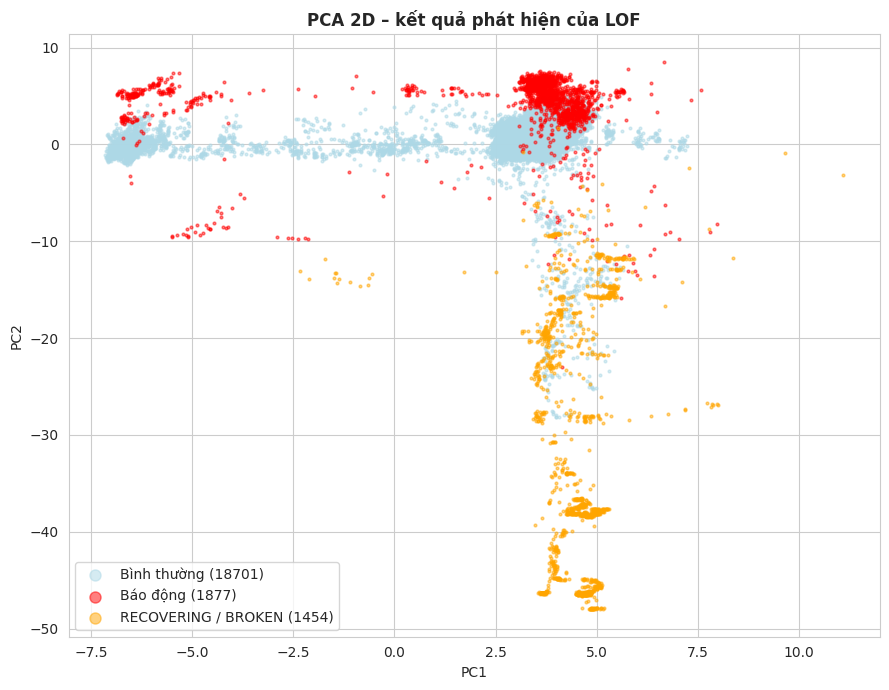

In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_fit)
P = pca.transform(X_all)
print('Phương sai giải thích bởi 2 thành phần:', pca.explained_variance_ratio_.round(3), '→ tổng', pca.explained_variance_ratio_.sum().round(3))

groups = {
    'Bình thường': (data['status'] == 'NORMAL').values & (al_best == 0).values,
    'Báo động': (data['status'] == 'NORMAL').values & (al_best == 1).values,
    'RECOVERING / BROKEN': (data['status'] != 'NORMAL').values,
}
colors = {'Bình thường': 'lightblue', 'Báo động': 'red', 'RECOVERING / BROKEN': 'orange'}
plt.figure(figsize=(9, 7))
for g, mask in groups.items():
    plt.scatter(P[mask, 0], P[mask, 1], s=4, alpha=0.5, c=colors[g], label=f'{g} ({mask.sum()})')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(markerscale=4)
plt.title(f'PCA 2D – kết quả phát hiện của {best_model}', fontweight='bold')
plt.tight_layout(); plt.show()

📌 **Notes (PCA 2D):**
* 2 thành phần chính giải thích **53,7%** phương sai (PC1 38,9%, PC2 14,8%).
* Dữ liệu bình thường tạo thành **các cụm lớn** dọc theo PC1 (ứng với các chế độ vận hành khác nhau của máy).
* Các khung RECOVERING/BROKEN trải dài xuống phía **PC2 âm** – máy dừng nên giá trị cảm biến khác hẳn lúc chạy.
* Các khung **bị LOF báo động (1.877 khung)** tập trung thành một vùng riêng phía **PC2 dương**, tách khỏi cả cụm bình thường lẫn vùng RECOVERING – đây chủ yếu là giai đoạn 19/06–28/06 khi `sensor_51` bất thường. Điều này cho thấy LOF đã nhận ra một trạng thái vận hành **khác với mọi trạng thái bình thường đã học**.

## 4. So sánh các mô hình

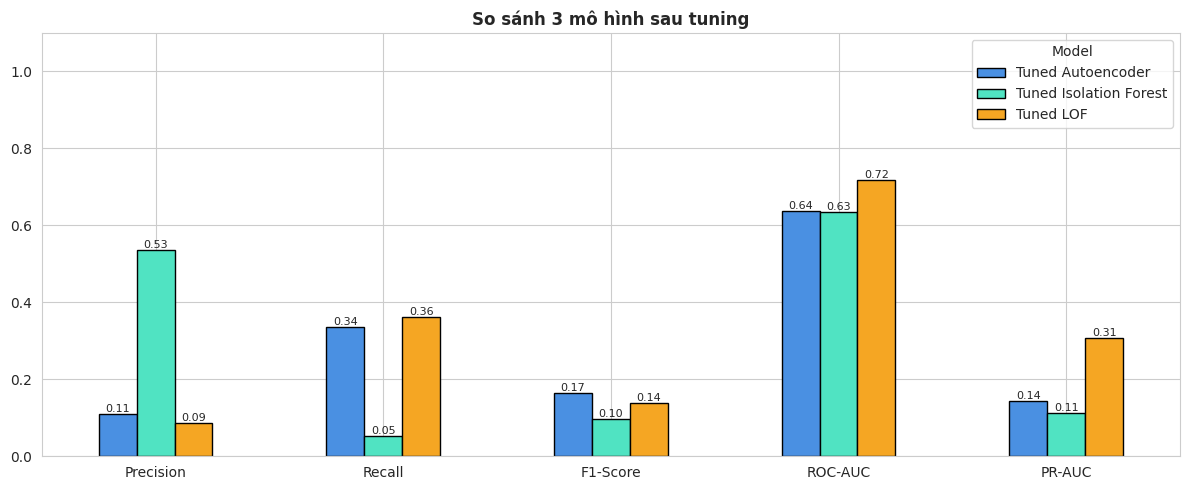

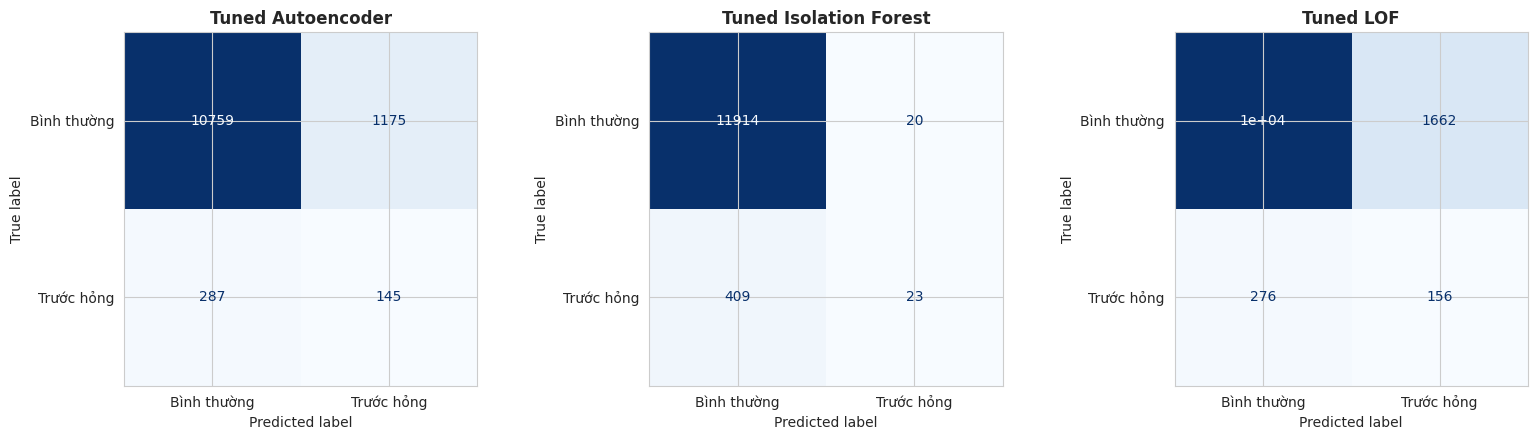

,Model,Detected,Mean lead (h),False alarms/day,Alarm time %,params
0,Tuned Autoencoder,2/3,12.083,0.084,9.846,"bottleneck=16, pct=99.5, persist=1"
1,Tuned Isolation Forest,1/3,3.833,0.024,0.168,"n_estimators=500, max_samples=1024, pct=99.5, ..."
2,Tuned LOF,3/3,21.167,2.039,13.927,"n_neighbors=100, pct=99, persist=1"


In [27]:
metrics = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']
plot_df = tuning_results_df.set_index('Model')[metrics]
ax = plot_df.T.plot(kind='bar', figsize=(12, 5), edgecolor='black', color=['#4A90E2', '#50E3C2', '#F5A623'])
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8)
plt.title('So sánh 3 mô hình sau tuning', fontweight='bold'); plt.xticks(rotation=0); plt.ylim(0, 1.1)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
y_true = data.loc[eval_mask, 'pre_failure'].values
for ax, m in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_true, best_alarms[m].values[eval_mask]),
                           display_labels=['Bình thường', 'Trước hỏng']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Tuned {m}', fontweight='bold')
plt.tight_layout(); plt.show()

tuning_results_df[['Model', 'Detected', 'Mean lead (h)', 'False alarms/day', 'Alarm time %', 'params']]

📌 **Notes (So sánh 3 mô hình sau tuning):**
* **LOF** có ROC-AUC (0,718) và PR-AUC (0,307) cao nhất – tức là xếp hạng các khung "trước hỏng" tốt nhất – và là mô hình duy nhất phát hiện được 3/3 lần hỏng.
* **Autoencoder** cân bằng nhất giữa phát hiện (2/3) và báo nhầm (0,08 đợt/ngày).
* **Isolation Forest** có precision cao nhất (0,535) nhưng recall rất thấp (0,053): báo động ít mà chắc, nhưng bỏ sót nhiều.
* Confusion matrix cho thấy số khung "trước hỏng" bị bỏ sót (FN) vẫn lớn ở cả 3 mô hình – hợp lý vì nhiều khung trong cửa sổ 24 giờ không có biểu hiện bất thường.

# 📌 KẾT LUẬN
1. **So sánh mô hình:**
   * **LOF** (`n_neighbors=100`) phát hiện được **3/3** lần hỏng trong tập test, cảnh báo sớm trung bình **21,2 giờ**, nhưng báo động 13,9% thời gian (~2 đợt báo nhầm/ngày); ROC-AUC 0,718 và PR-AUC 0,307 cao nhất.
   * **Autoencoder** (`bottleneck=16`) phát hiện **2/3**, báo nhầm ít nhất trong các mô hình nhạy (0,08 đợt/ngày).
   * **Isolation Forest** chỉ phát hiện **1/3** nhưng gần như không báo nhầm (0,17% thời gian).
2. **Hiệu quả tuning:** chọn cấu hình theo mục tiêu bảo trì (phát hiện nhiều lần hỏng, ít báo nhầm) thay vì F1 giúp LOF tăng từ 2/3 lên 3/3 và Autoencoder từ 1/3 lên 2/3. Yếu tố quyết định là **quy tắc báo động** (ngưỡng, persist) hơn là tham số mô hình.
3. **Cảm biến chủ chốt:** `sensor_04`, `sensor_00`, `sensor_05` lệch mạnh nhất trước khi hỏng; `sensor_51` (chạm giá trị lớn nhất của thang đo) cho dấu hiệu sớm nhất (~9 ngày trước lần hỏng 28/06).
4. **Đề xuất bảo trì dự đoán:**
   * Dùng **2 tầng**: Autoencoder làm cảnh báo chính (ít báo nhầm); LOF làm cảnh báo phụ (nhạy hơn) để kỹ thuật viên theo dõi.
   * Ngoài mô hình, đặt **cảnh báo theo luật** cho các tình huống rõ ràng: cảm biến chạm giá trị tối đa của thang đo (như `sensor_51` = 1000) hoặc `sensor_04`/`sensor_00` giảm liên tục.
   * Khi có báo động: kiểm tra trước các bộ phận gắn với `sensor_04`, `sensor_00`, `sensor_05`, lên lịch bảo trì trước khi máy dừng.
   * **Huấn luyện lại mô hình định kỳ** (ví dụ sau mỗi đợt sửa chữa lớn) vì trạng thái bình thường của máy thay đổi theo thời gian.
5. **Hạn chế:**
   * Chỉ có 7 lần hỏng (3 lần trong test) → kết quả đánh giá chưa thật chắc chắn; việc chọn cấu hình trên giai đoạn test có thể làm kết quả lạc quan.
   * Tên và đơn vị đo của cảm biến bị ẩn danh nên chưa gắn được kết quả với bộ phận vật lý cụ thể; không biết loại hỏng hóc của từng lần.
   * Các sự cố đột ngột (08/07, 25/07) gần như không có dấu hiệu báo trước trong dữ liệu cảm biến.
   * Cửa sổ đánh giá 24 giờ chưa ghi nhận được các dấu hiệu sớm hơn (như `sensor_51` ~9 ngày trước hỏng).